# Agrupamiento de tumores mamarios a partir de características nucleares

**Actividad 1 · Técnicas de Análisis No Supervisado**
Especialización en Análisis Estadístico para Ciencia de Datos · Universidad de La Salle

Notebook anexo del informe ejecutivo. Problema 3: un laboratorio de diagnóstico necesita identificar patrones que permitan clasificar de manera preliminar los tumores en subgrupos para sugerir rutas de análisis.

## 1. Configuración del entorno

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 

# Preprocesamiento 
from sklearn.preprocessing import PowerTransformer
from sklearn.decomposition import PCA

# Algoritmos 
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors

# Distancias y jerarquía 
from scipy.spatial.distance import pdist, cdist
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet

# Métricas de validación 
from sklearn.metrics import (silhouette_score, silhouette_samples,
                            davies_bouldin_score, calinski_harabasz_score,
                            adjusted_rand_score, normalized_mutual_info_score,
                            homogeneity_completeness_v_measure)

# Paquetes del proyecto: rutas y funciones de carga 
from breast_cancer_clustering.config import SEMILLA, ARCHIVO_DEPURADO, ruta_figuras
from breast_cancer_clustering.datos import cargar_crudos

# Configuración de la sesión
np.random.seed(SEMILLA)
pd.set_option("display.max_columns", 30)
pd.options.display.float_format = "{:,.4f}".format
sns.set_theme(style="whitegrid", context="notebook")
FIGURAS = ruta_figuras(1)

## 2. Problema, base de datos y objetivo
### 2.1 Carga de datos

In [2]:
df = cargar_crudos()
print(f"{df.shape[0]} filas x {df.shape[1]} columnas")
print(df["diagnosis"].value_counts())
df.head()

569 filas x 32 columnas
diagnosis
B    357
M    212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,...,compactness_se,concavity_se,concave_points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.9900,10.3800,122.8000,"1,001.0000",0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,...,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,"2,019.0000",0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,842517,M,20.5700,17.7700,132.9000,"1,326.0000",0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,...,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,"1,956.0000",0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,84300903,M,19.6900,21.2500,130.0000,"1,203.0000",0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,...,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,"1,709.0000",0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,84348301,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,...,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,84358402,M,20.2900,14.3400,135.1000,"1,297.0000",0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,...,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,"1,575.0000",0.1374,0.2050,0.4000,0.1625,0.2364,0.0768


### 2.2 Descripción de la base

La base Breast Cancer Wisconsin contiene 569 observaciones, cada una correspondiente a una masa mamaria muestreada mediante aspiración con aguja fina (Wolberg, Mangasarian, et al., 1995). A partir de la imagen digitalizada de cada muestra se calcularon diez características de los núcleos celulares, como el radio, la textura, la concavidad y la dimensión fractal; de cada una se reporta la media, el error estándar y el valor "peor", definido como el promedio de los tres valores más grandes, lo que da 30 variables cuantitativas (Street et al., 1993). Adicionalmente, la base incluye el diagnóstico confirmado de cada masa, con 357 casos benignos (62,7 %) y 212 malignos (37,3 %).

Esta base permite abordar el problema 3 porque describe cada tumor únicamente a partir de la morfología de sus núcleos, que es la información disponible antes del diagnóstico definitivo. Por lo tanto, es posible agrupar los tumores sin usar el diagnóstico y, en una etapa posterior, emplear ese diagnóstico como referencia externa para evaluar si los grupos encontrados tienen sentido clínico.

### 2.3 Objetivo del agrupamiento

El objetivo del agrupamiento es identificar subgrupos de tumores con perfiles nucleares similares que sirvan como una primera clasificación orientadora para el laboratorio. Teniendo esto en cuenta, no se busca reemplazar el diagnóstico citológico, sino proponer una segmentación que permita dar prioridad a rutas de análisis; por ejemplo, la revisión urgente para subgrupos con perfiles asociados a malignidad y seguimiento rutinario para los de perfil benigno. Para ello, el número de grupos se determinará con criterios internos de validación y no se fijará de antemano, mientras que el diagnóstico se reservará exclusivamente para la validación externa.

### 2.4 Separación de la etiqueta externa

In [3]:
# Se separa el diagnóstico como etiqueta externa; no interviene en el agrupamiento
y_ext = df["diagnosis"]
df_cluster = df.drop(columns=["id", "diagnosis"])
print(f"Variables para el agrupamiento: {df_cluster.shape[1]}")

Variables para el agrupamiento: 30


## 3. Clasificación de variables

In [4]:
# Descripción de cada medida nuclear según la documentación de la base (wdbc.names)
DESCRIPCIONES = {
    "radius": "Media de las distancias del centro a los puntos del contorno",
    "texture": "Desviación estándar de los valores en escala de grises",
    "perimeter": "Perímetro del contorno nuclear",
    "area": "Área del núcleo",
    "smoothness": "Variación local en las longitudes del radio",
    "compactness": "Perímetro² / área − 1",
    "concavity": "Severidad de las porciones cóncavas del contorno",
    "concave_points": "Número de porciones cóncavas del contorno",
    "symmetry": "Simetría del núcleo",
    "fractal_dimension": "Aproximación de línea de costa − 1",
}

filas = [
    {"Variable": "id", "Descripción": "Identificador de la muestra",
     "Tipo": "Cualitativa", "Subtipo": "Nominal", "Escala": "Nominal",
     "Rol": "Se excluye"},
    {"Variable": "diagnosis", "Descripción": "Diagnóstico: M = maligno, B = benigno",
     "Tipo": "Cualitativa", "Subtipo": "Nominal dicotómica", "Escala": "Nominal",
     "Rol": "Etiqueta externa (solo validación)"},
]
for medida, descripcion in DESCRIPCIONES.items():
    filas.append({"Variable": f"{medida}_mean / _se / _worst", "Descripción": descripcion,
                  "Tipo": "Cuantitativa", "Subtipo": "Continua", "Escala": "Razón",
                  "Rol": "Candidata al agrupamiento"})

clasificacion = pd.DataFrame(filas)
clasificacion

,Variable,Descripción,Tipo,Subtipo,Escala,Rol
0,id,Identificador de la muestra,Cualitativa,Nominal,Nominal,Se excluye
1,diagnosis,"Diagnóstico: M = maligno, B = benigno",Cualitativa,Nominal dicotómica,Nominal,Etiqueta externa (solo validación)
2,radius_mean / _se / _worst,Media de las distancias del centro a los punto...,Cuantitativa,Continua,Razón,Candidata al agrupamiento
3,texture_mean / _se / _worst,Desviación estándar de los valores en escala d...,Cuantitativa,Continua,Razón,Candidata al agrupamiento
4,perimeter_mean / _se / _worst,Perímetro del contorno nuclear,Cuantitativa,Continua,Razón,Candidata al agrupamiento
5,area_mean / _se / _worst,Área del núcleo,Cuantitativa,Continua,Razón,Candidata al agrupamiento
6,smoothness_mean / _se / _worst,Variación local en las longitudes del radio,Cuantitativa,Continua,Razón,Candidata al agrupamiento
7,compactness_mean / _se / _worst,Perímetro² / área − 1,Cuantitativa,Continua,Razón,Candidata al agrupamiento
8,concavity_mean / _se / _worst,Severidad de las porciones cóncavas del contorno,Cuantitativa,Continua,Razón,Candidata al agrupamiento
9,concave_points_mean / _se / _worst,Número de porciones cóncavas del contorno,Cuantitativa,Continua,Razón,Candidata al agrupamiento


Cada una de las diez medidas aparece tres veces en la base: `_mean` es el promedio de todos los núcleos de la imagen, `_se` su error estándar y `_worst` el promedio de los tres valores más grandes (Street et al., 1993).

### 3.1 Variables más relevantes

Desde el conocimiento del dominio, se espera que las variables de tamaño (radio, perímetro y área) y las de irregularidad del contorno (concavidad, puntos cóncavos y compacidad) sean las más informativas, dado que los núcleos malignos tienden a ser más grandes y a presentar contornos más irregulares que los benignos (Wolberg, Street, et al., 1995). En la misma línea, los autores de la base obtuvieron la mejor separación entre diagnósticos con solo tres variables: área peor, suavidad peor y textura media (Wolberg, Mangasarian, et al., 1995). Sin embargo, el radio, el perímetro y el área son funciones geométricas de una misma dimensión, por lo que se anticipa una fuerte redundancia entre ellas que deberá verificarse en el análisis exploratorio antes de decidir cuáles incluir en el agrupamiento.

## 4. Análisis exploratorio

### 4.1 Calidad de los datos

In [5]:
resumen_calidad = pd.DataFrame({
    "nulos": df_cluster.isna().sum(),
    "porcentaje_nulos": df_cluster.isna().mean() * 100,
    "ceros": (df_cluster==0).sum(),
})

print(f"Cantidad de duplicados: {df_cluster.duplicated().sum()}\n")
display(resumen_calidad)


Cantidad de duplicados: 0



,nulos,porcentaje_nulos,ceros
radius_mean,0,0.0000,0
texture_mean,0,0.0000,0
perimeter_mean,0,0.0000,0
area_mean,0,0.0000,0
smoothness_mean,0,0.0000,0
compactness_mean,0,0.0000,0
concavity_mean,0,0.0000,13
concave_points_mean,0,0.0000,13
symmetry_mean,0,0.0000,0
fractal_dimension_mean,0,0.0000,0


In [6]:
# Se verifica si los ceros se concentran en los mismos tumores
cols_cero = df_cluster.columns[(df_cluster == 0).any()]
filas_cero = (df_cluster[cols_cero] == 0).any(axis=1)
mismas_filas = (df_cluster[cols_cero] == 0).eq(filas_cero, axis=0).all().all()

print(f"Variables con ceros: {list(cols_cero)}")
print(f"Tumores con algún cero: {filas_cero.sum()} | ¿los mismos en todas las variables?: {mismas_filas}")
print(f"Diagnóstico de esos tumores (solo descriptivo): {y_ext[filas_cero].value_counts().to_dict()}")

Variables con ceros: ['concavity_mean', 'concave_points_mean', 'concavity_se', 'concave_points_se', 'concavity_worst', 'concave_points_worst']
Tumores con algún cero: 13 | ¿los mismos en todas las variables?: True
Diagnóstico de esos tumores (solo descriptivo): {'B': 13}


La base no presenta valores faltantes ni registros duplicados, por lo que no requiere imputación ni depuración de casos. A pesar de esto, las variables concavidad y puntos cóncavos, en sus versiones de media, error estándar y peor, presentan ceros de los cuales todos corresponden a los mismos 13 tumores. A partir de esto, se concluye que no se trata de datos faltantes sino de núcleos en los que no se detectaron porciones cóncavas en el contorno, lo cual es coherente con que los 13 casos tengan diagnóstico benigno, asociado a contornos regulares. Teniendo esto en cuenta, se decide conservar los ceros como valores válidos, sin embargo, se debe considerar que estos condicionan la elección de la transformación, ya que impiden aplicar el logaritmo directamente.

### 4.2 Descriptivos y asimetría

In [7]:
def extended_describe(data):
    # 1. Descripción estándar
    desc = data.describe()

    # 2. Cálculo de sesgo y coeficiente de variación
    skew = data.skew()
    cv = data.std() / data.mean()

    metricas_ad = pd.DataFrame([skew, cv], index=["skew", "cv"], columns=data.columns)

    return pd.concat([desc, metricas_ad])

descripcion = extended_describe(df_cluster).T.sort_values(by="skew", ascending=False)
display(descripcion)

,count,mean,std,min,25%,50%,75%,max,skew,cv
area_se,569.0000,40.3371,45.4910,6.8020,17.8500,24.5300,45.1900,542.2000,5.4472,1.1278
concavity_se,569.0000,0.0319,0.0302,0.0000,0.0151,0.0259,0.0420,0.3960,5.1105,0.9465
fractal_dimension_se,569.0000,0.0038,0.0026,0.0009,0.0022,0.0032,0.0046,0.0298,3.9240,0.6973
perimeter_se,569.0000,2.8661,2.0219,0.7570,1.6060,2.2870,3.3570,21.9800,3.4436,0.7054
radius_se,569.0000,0.4052,0.2773,0.1115,0.2324,0.3242,0.4789,2.8730,3.0886,0.6844
smoothness_se,569.0000,0.0070,0.0030,0.0017,0.0052,0.0064,0.0081,0.0311,2.3145,0.4264
symmetry_se,569.0000,0.0205,0.0083,0.0079,0.0152,0.0187,0.0235,0.0790,2.1951,0.4024
compactness_se,569.0000,0.0255,0.0179,0.0023,0.0131,0.0204,0.0324,0.1354,1.9022,0.7029
area_worst,569.0000,880.5831,569.3570,185.2000,515.3000,686.5000,"1,084.0000","4,254.0000",1.8594,0.6466
fractal_dimension_worst,569.0000,0.0839,0.0181,0.0550,0.0715,0.0800,0.0921,0.2075,1.6626,0.2152


A partir de la tabla descriptiva, se puede concluir que las variables difieren entre sí en varios órdenes de magnitud, siendo un ejemplo, la media de la variable área media la cual supera 650 mientras que la media de la suavidad del error estándar está alrededor de 0,007. Teniendo esto en cuenta, cualquier algoritmo que esté basado en distancias se vería dominado por las variables de mayor escala si a estas no se les aplica una estandarización previa. Adicionalmente, la asimetría se concentra en las variables de error estándar: area_se (5,45) y concavity_se (5,11) encabezan la tabla, seguidas del resto de variables _se y de area_worst, mientras que variables como smoothness_worst (0,42) se aproximan a la simetría.

### 4.3 Valores atípicos

In [8]:
# Regla de Tukey: valores fuera de [Q1 − 1,5·RIC, Q3 + 1,5·RIC]
q1, q3 = df_cluster.quantile(0.25), df_cluster.quantile(0.75)
ric = q3 - q1
atipicos = (df_cluster < q1 - 1.5 * ric) | (df_cluster > q3 + 1.5 * ric)

resumen_atipicos = atipicos.sum().sort_values(ascending=False).rename("n_atipicos").to_frame()
resumen_atipicos["porcentaje"] = resumen_atipicos["n_atipicos"] / len(df_cluster) * 100

con_atipico = atipicos.any(axis=1)
print(f"Tumores con al menos un valor atípico: {con_atipico.sum()} ({con_atipico.mean():.1%})")
display(resumen_atipicos.head(10))

Tumores con al menos un valor atípico: 171 (30.1%)


,n_atipicos,porcentaje
area_se,65,11.4236
radius_se,38,6.6784
perimeter_se,38,6.6784
area_worst,35,6.1511
smoothness_se,30,5.2724
fractal_dimension_se,28,4.9209
compactness_se,28,4.9209
symmetry_se,27,4.7452
area_mean,25,4.3937
fractal_dimension_worst,24,4.2179


Según la regla de Tukey (1977), 171 tumores (30,1 %) presentan al menos un valor atípico, y estos se concentran nuevamente en las variables de error estándar y de área, con area_se a la cabeza (65 casos). Teniendo en cuenta que estos valores extremos representan casi la tercera parte de la muestra y además que en este contexto pueden corresponder a tumores de interés clínico, se toma la decisión de conservarlos reduciendo su influencia a partir de una transformación en lugar de eliminarlos.

### 4.4 Distribución de las variables

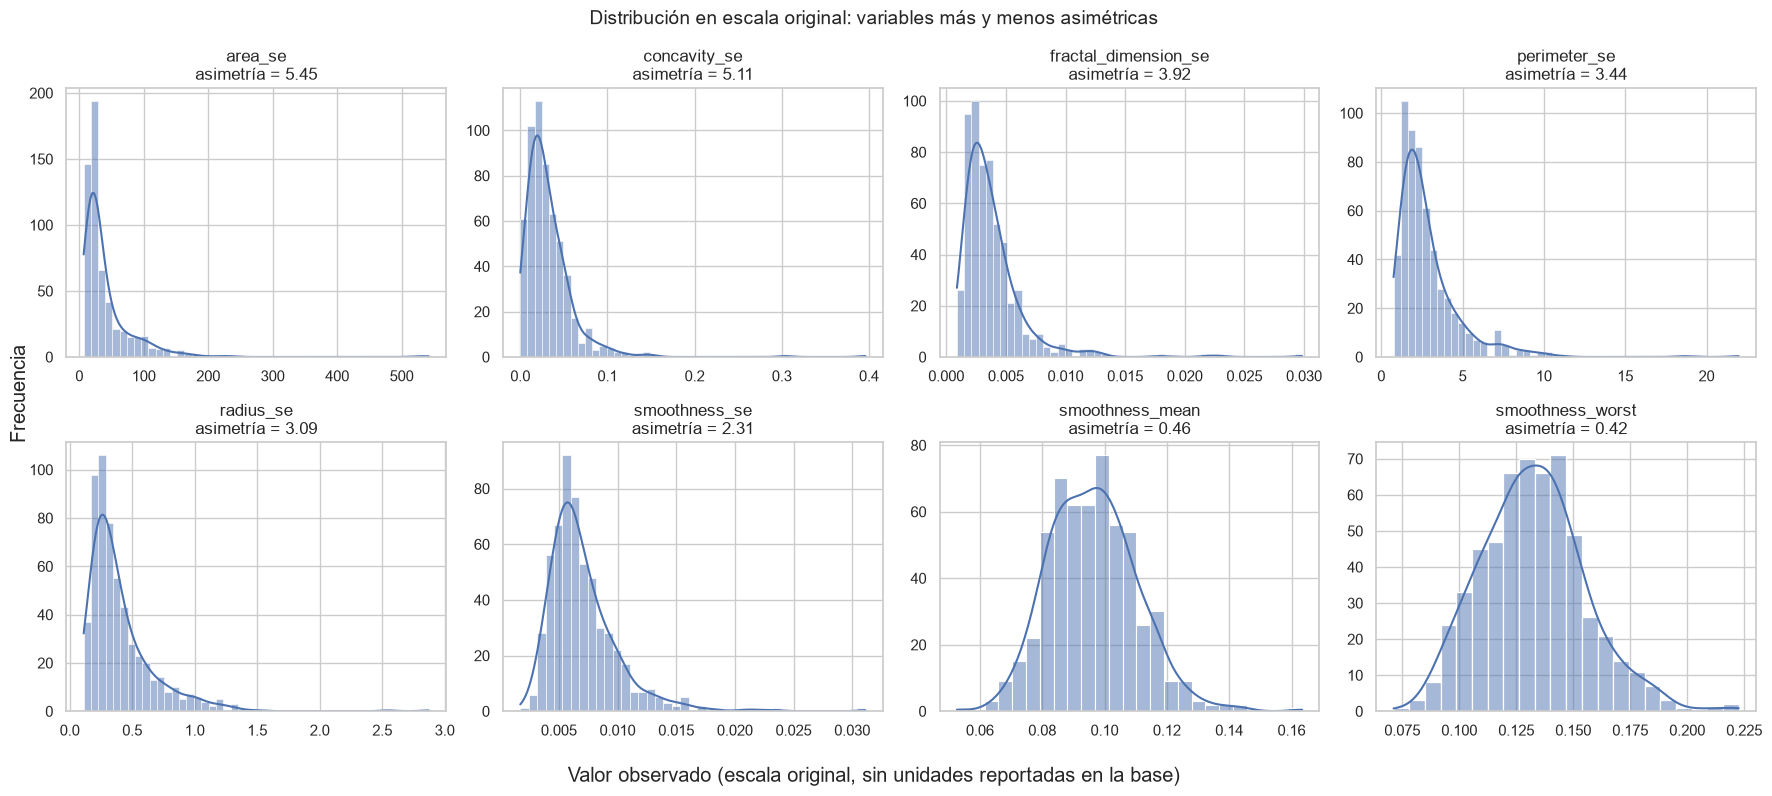

In [9]:
# Contraste: las seis variables más asimétricas frente a las dos más simétricas
variables_hist = list(descripcion.head(6).index) + list(descripcion.tail(2).index)

fig, axs = plt.subplots(2, 4, figsize=(18, 8))

for ax, variable in zip(axs.ravel(), variables_hist):
    valores = df_cluster[variable]
    sns.histplot(valores, kde=True, ax=ax)
    ax.set(title=f"{variable}\nasimetría = {valores.skew():.2f}", xlabel="", ylabel="")

fig.suptitle("Distribución en escala original: variables más y menos asimétricas", fontsize=14)
fig.supxlabel("Valor observado (escala original, sin unidades reportadas en la base)")
fig.supylabel("Frecuencia")
fig.tight_layout()
plt.savefig(FIGURAS / "histogramas_asimetria.png", dpi=150, bbox_inches="tight")
plt.show()

La asimetría es positiva en las 30 variables, es decir, todas presentan una cola hacia los valores altos, y en 22 de ellas supera 1. Este comportamiento es más marcado en las variables de error estándar, ya que las seis más asimétricas son de este tipo, encabezadas por area_se (5,45) y concavity_se (5,11), y en ellas la mayoría de los tumores se concentra en valores bajos mientras unos pocos casos se extienden hasta varias veces la mediana. En contraste, la suavidad media y "peor" muestran distribuciones aproximadamente simétricas (0,46 y 0,42). Con lo que respecta a las variables de concavidad los 13 ceros se ubican en el extremo izquierdo de la distribución. En conjunto, estos resultados plantean la necesidad de evaluar en el preprocesamiento una transformación que reduzca la asimetría y que, a la vez, admita valores iguales a cero.

### 4.5 Correlación entre variables

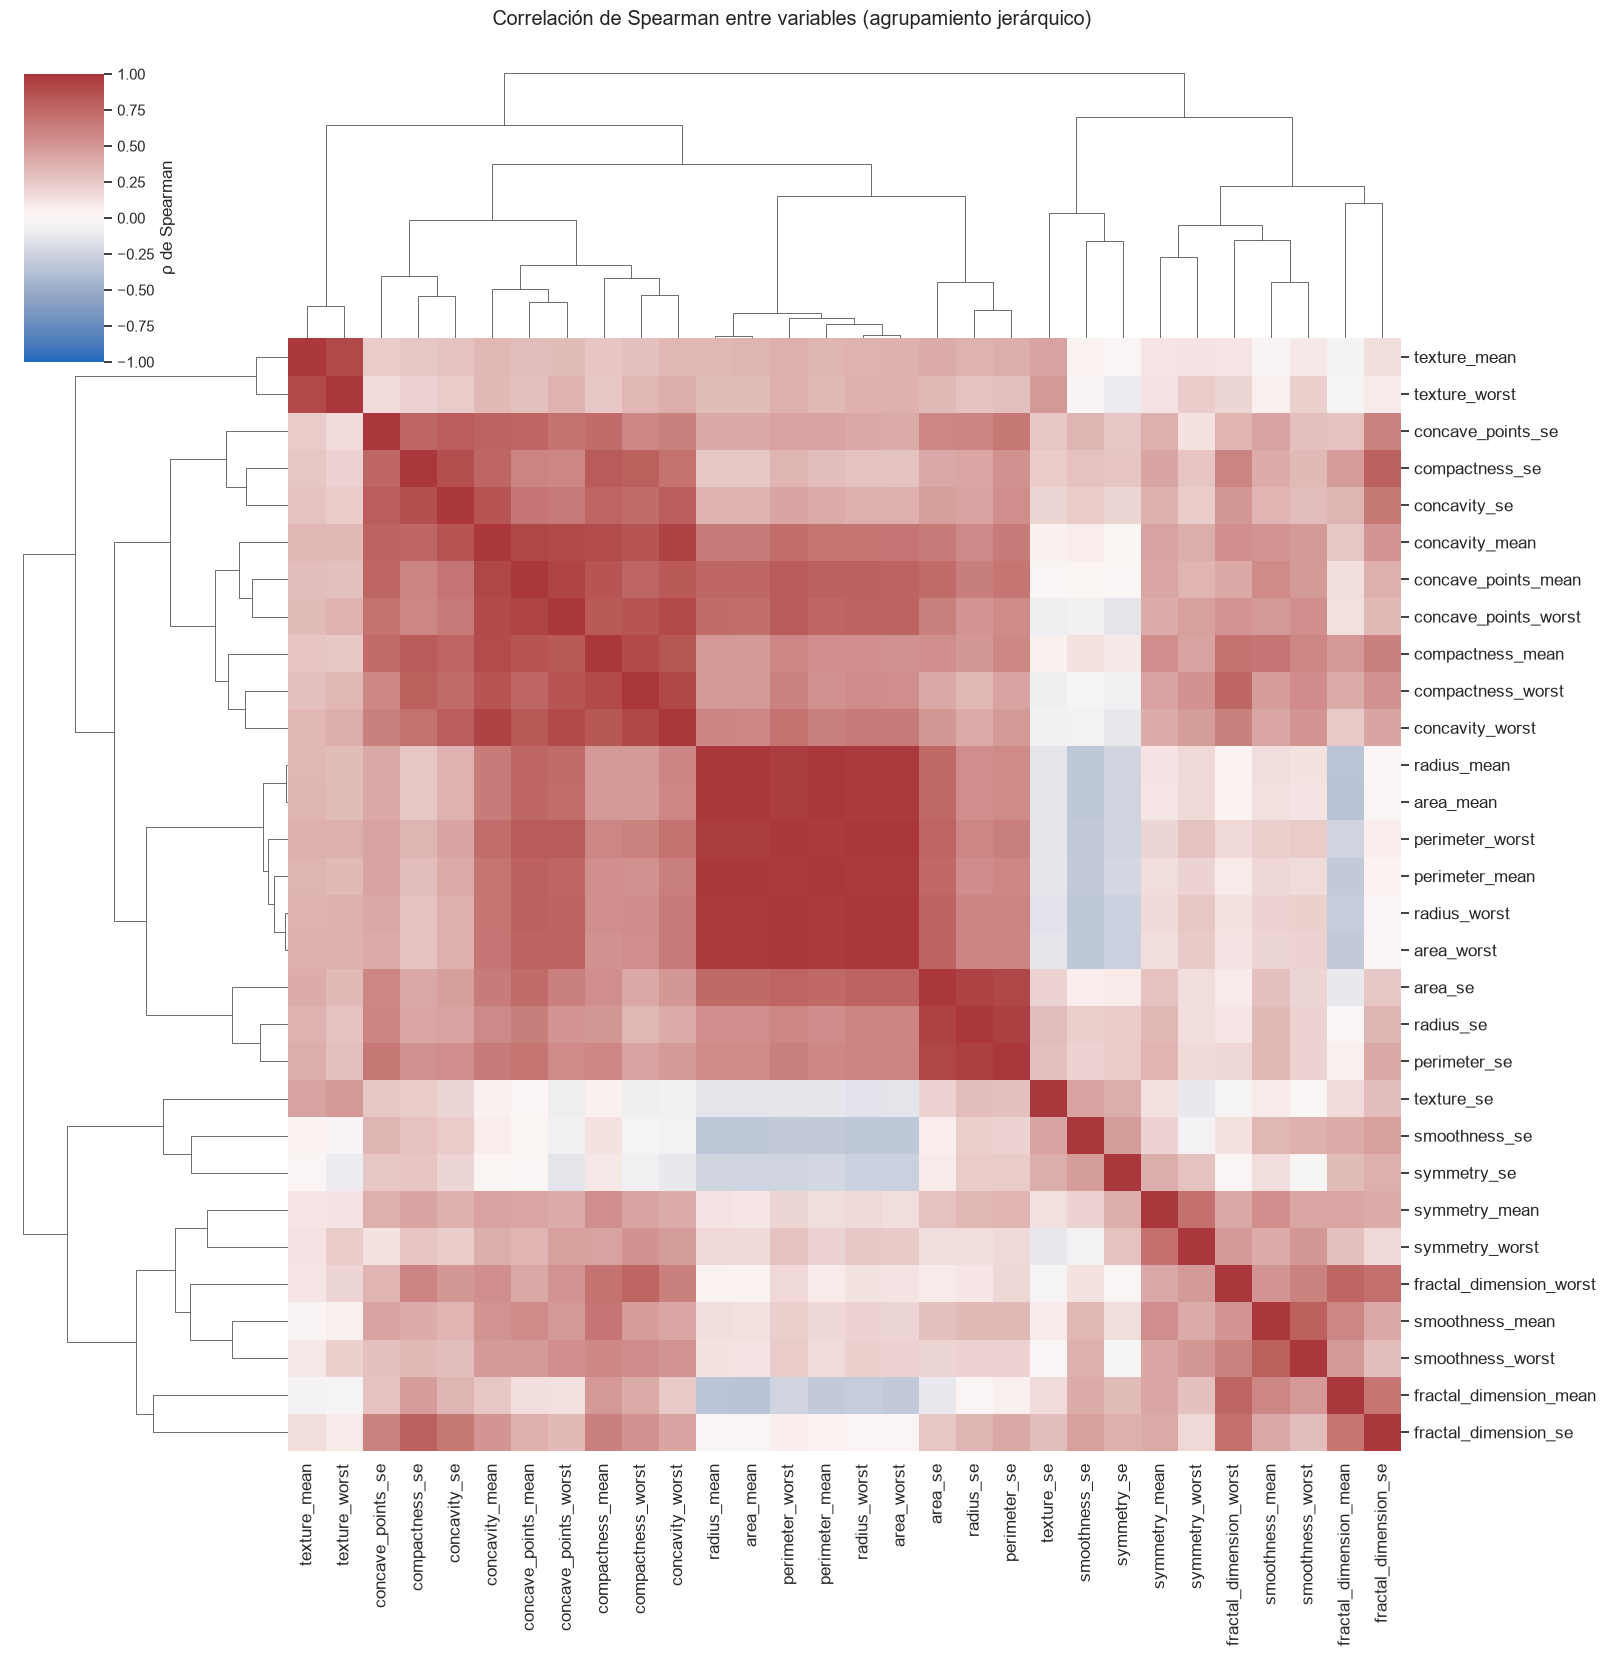

In [10]:
matriz_correlacion = df_cluster.corr(method="spearman")

g = sns.clustermap(
    matriz_correlacion, cmap="vlag", vmin=-1, vmax=1, center=0,
    xticklabels=True, yticklabels=True, figsize=(16, 16),
    cbar_kws={"label": "ρ de Spearman"}
)

g.ax_heatmap.tick_params(labelsize=12)
g.figure.suptitle("Correlación de Spearman entre variables (agrupamiento jerárquico)", y=1.02)
g.savefig(FIGURAS / "correlacion_clustermap.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
# Se toma solo el triángulo superior para no repetir pares
umbral = 0.9
triangulo = np.triu(np.ones(matriz_correlacion.shape, dtype=bool), k=1)
pares = matriz_correlacion.where(triangulo).stack().rename("rho").reset_index()
pares.columns = ["variable_1", "variable_2", "rho"]
pares_altos = pares[pares["rho"].abs() >= umbral].sort_values("rho", key=abs, ascending=False)

print(f"Pares con |ρ| ≥ {umbral}: {len(pares_altos)}")
display(pares_altos)

Pares con |ρ| ≥ 0.9: 26


,variable_1,variable_2,rho
3,radius_mean,area_mean,0.9996
623,radius_worst,area_worst,0.9989
2,radius_mean,perimeter_mean,0.9978
63,perimeter_mean,area_mean,0.9971
622,radius_worst,perimeter_worst,0.9935
683,perimeter_worst,area_worst,0.9924
80,perimeter_mean,radius_worst,0.9812
83,perimeter_mean,area_worst,0.9809
113,area_mean,area_worst,0.9803
110,area_mean,radius_worst,0.9793


Dado que las variables presentan asimetría y valores atípicos, la asociación entre ellas se evaluó con el coeficiente de Spearman, que trabaja sobre rangos y capta relaciones monótonas sin exigir linealidad ni normalidad (Schober et al., 2018). A partir de la matriz de correlación de Spearman, se realizó un agrupamiento jerárquico del mapa, el cual reveló cuatro bloques principales. El primero, y el más fuerte, representa el tamaño a partir de variables como el radio, el perímetro y el área, las cuales en sus versiones "media" y "peor" se correlacionan con ρ ≥ 0,97, lo que confirma que son funciones geométricas de una misma dimensión. Por otro lado, el segundo grupo está conformado por la irregularidad del contorno con variables como la concavidad, puntos cóncavos y la compacidad, cuyas correlaciones se encuentran entre 0,90 y 0,94. Con lo que respecta a la textura media y peor estas forman un par aislado (ρ = 0,91), mientras que la suavidad, la simetría y la dimensión fractal se asocian débilmente con el tamaño; la dimensión fractal media incluso muestra una relación negativa con el radio (ρ = −0,35). En total, 26 pares superan |ρ| ≥ 0,9, de modo que incluir todas las variables duplicaría el peso del tamaño y del contorno en el cálculo de distancias.

### 4.6 Hallazgos que guían el preprocesamiento

En síntesis, el análisis exploratorio orienta cuatro decisiones para la siguiente fase:

1. **Reducción de redundancia:** conservar una sola variable por bloque altamente correlacionado, en particular una de tamaño en lugar de radio, perímetro y área simultáneamente.
2. **Bloque de estadísticos:** elegir entre las versiones `_mean` y `_worst`, que se correlacionan fuertemente entre sí, y valorar si se excluyen las `_se`, que concentran la mayor asimetría y los atípicos.
3. **Transformación:** evaluar una transformación que corrija la asimetría y admita valores iguales a cero, de modo que no se descarten los 13 tumores sin concavidades.
4. **Escalado:** estandarizar todas las variables, dado que sus magnitudes difieren en varios órdenes.

Los valores atípicos se conservan, ya que representan cerca del 30 % de la muestra.

## 5. Preprocesamiento

El preprocesamiento sigue el orden que definieron los hallazgos del análisis exploratorio: primero se seleccionan las variables, en tres pasos que no utilizan el diagnóstico, y después se transforman y estandarizan las que conforman el modelo.

### 5.1 Selección del bloque de variables

En primer lugar, se excluyen las diez variables de error estándar. Dado que el error estándar equivale a la desviación entre núcleos dividida por la raíz del número de núcleos medidos en la imagen, su valor depende en parte de cuántos núcleos se capturaron y no solo de la morfología del tumor (Street et al., 1993); además, el análisis exploratorio mostró que estas variables concentran la mayor asimetría y la mayoría de los valores atípicos.

En segundo lugar, entre las versiones media y peor se conserva el bloque `_mean`. Por un lado, sus diez medidas son menos redundantes entre sí (|ρ| promedio de 0,47 frente a 0,51 en el bloque `_worst`), de modo que aportan información más complementaria; por otro, describen el núcleo típico de cada muestra, mientras que el valor peor depende únicamente de los tres núcleos más extremos y es, por tanto, más sensible a núcleos aislados. Finalmente, el bloque `_mean` facilita la interpretación de los perfiles de cada grupo. Cabe aclarar que los autores de la base obtuvieron su mejor separación con una combinación de variables medias y peores (Wolberg, Mangasarian, et al., 1995); sin embargo, esa combinación se eligió maximizando la clasificación del diagnóstico, por lo que adoptarla aquí haría circular la validación externa.

In [12]:
# Se descartan las variables _se y _worst; se conserva el bloque _mean
VARS_MEAN = [col for col in df_cluster.columns if col.endswith("_mean")]
print(f"Variables del bloque _mean: {len(VARS_MEAN)}")
print(VARS_MEAN)

Variables del bloque _mean: 10
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean']


### 5.2 Reducción de redundancia

In [13]:
# Pares redundantes dentro del bloque _mean (mismo umbral |ρ| ≥ 0,9 de la sección 4.5)
pares_mean = pares_altos[
    pares_altos["variable_1"].isin(VARS_MEAN) & pares_altos["variable_2"].isin(VARS_MEAN)
]
display(pares_mean)

# Asimetría de las variables implicadas, usada como criterio de desempate
implicadas = pd.unique(pares_mean[["variable_1", "variable_2"]].values.ravel())
display(descripcion.loc[implicadas, ["skew"]].sort_values("skew"))

,variable_1,variable_2,rho
3,radius_mean,area_mean,0.9996
2,radius_mean,perimeter_mean,0.9978
63,perimeter_mean,area_mean,0.9971
187,concavity_mean,concave_points_mean,0.9274


,skew
radius_mean,0.9424
perimeter_mean,0.9907
concave_points_mean,1.1712
concavity_mean,1.4012
area_mean,1.6457


Dentro del bloque _mean, cuatro pares superan el umbral de |ρ| ≥ 0,9. Tres de ellos corresponden al bloque de tamaño descrito previamente (radio, perímetro y área, con ρ ≥ 0,997), por lo que basta conservar una sola de estas variables, en este caso se elige el radio porque es la menos asimétrica de las tres (0,94 frente a 0,99 del perímetro y 1,65 del área). Con lo que respecta al cuarto par este une la concavidad con los puntos cóncavos (ρ = 0,93); en este caso se conservan los puntos cóncavos, ya que presentan menor asimetría (1,17 frente a 1,40) y la concavidad es, además, la variable del bloque de contorno más cercana a la compacidad. Teniendo en cuenta lo anterior, el modelo trabaja con siete variables que representan tamaño, textura, regularidad del contorno, simetría y complejidad del borde nuclear.

In [14]:
# Se elimina una variable por par redundante
ELIMINADAS = ["perimeter_mean", "area_mean", "concavity_mean"]
VARS_MODELO = [v for v in VARS_MEAN if v not in ELIMINADAS]

# Verificación: ningún par restante alcanza el umbral
corr_modelo = matriz_correlacion.loc[VARS_MODELO, VARS_MODELO].abs()
triangulo_modelo = np.triu(np.ones(corr_modelo.shape, dtype=bool), k=1)
max_rho = corr_modelo.where(triangulo_modelo).max().max()

print(f"Variables del modelo ({len(VARS_MODELO)}): {VARS_MODELO}")
print(f"Máxima |ρ| entre variables del modelo: {max_rho:.3f}")

Variables del modelo (7): ['radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean']
Máxima |ρ| entre variables del modelo: 0.848


### 5.3 Transformación

In [15]:
X_sel = df_cluster[VARS_MODELO]

# Yeo-Johnson sin estandarizar, para comparar únicamente el efecto sobre la forma
yj = PowerTransformer(method="yeo-johnson", standardize=False).fit(X_sel)
X_yj = pd.DataFrame(yj.transform(X_sel), columns=VARS_MODELO)

comparacion_asimetria = pd.DataFrame({
    "original": X_sel.skew(),
    "log1p": np.log1p(X_sel).skew(),
    "yeo_johnson": X_yj.skew(),
    "lambda": yj.lambdas_,
}, index=VARS_MODELO)
display(comparacion_asimetria)

,original,log1p,yeo_johnson,lambda
radius_mean,0.9424,0.3487,0.0082,-0.5701
texture_mean,0.6504,0.0187,0.0002,-0.0307
smoothness_mean,0.4563,0.4065,-0.0096,-9.1345
compactness_mean,1.1901,1.0432,0.1056,-8.6640
concave_points_mean,1.1712,1.0832,0.1987,-14.2555
symmetry_mean,0.7256,0.6327,-0.0167,-7.7350
fractal_dimension_mean,1.3045,1.2723,0.0362,-55.0722


La transformación de Yeo-Johnson lleva la asimetría de las siete variables a valores cercanos a cero; por ejemplo, la dimensión fractal pasa de 1,30 a 0,04 y la compacidad de 1,19 a 0,11. A diferencia del logaritmo, esta transformación admite valores iguales a cero, lo que permite conservar los 13 tumores sin concavidades (Yeo y Johnson, 2000). En contraste, log(1 + x) resulta insuficiente para las variables de magnitud pequeña, ya que en ese rango se comporta de forma casi lineal: la asimetría de la dimensión fractal solo baja a 1,27 y la de los puntos cóncavos a 1,08. Teniendo en cuenta los resultados que ofrece Yeo-Johnson con respecto a la asimetría se adopta este método de transformación para aplicarlo sobre todas las variables que serán empleadas en el modelo.

### 5.4 Estandarización

In [16]:
# Yeo-Johnson y estandarización en un solo transformador, reutilizable para casos nuevos
transformador = PowerTransformer(method="yeo-johnson", standardize=True)
X = transformador.fit_transform(X_sel)

# Verificación: media 0 y desviación estándar 1 en cada variable
display(pd.DataFrame(X, columns=VARS_MODELO).agg(["mean", "std"]).T.round(3))

,mean,std
radius_mean,0.0000,1.0010
texture_mean,0.0000,1.0010
smoothness_mean,-0.0000,1.0010
compactness_mean,0.0000,1.0010
concave_points_mean,0.0000,1.0010
symmetry_mean,0.0000,1.0010
fractal_dimension_mean,0.0000,1.0010


Después de la transformación, cada variable se estandariza a media 0 y desviación estándar 1, siendo esta una decisión necesaria ya que los algoritmos de agrupamiento empleados en los modelos se basan en distancias euclidianas y en las cuales las variables de mayor escala dominan el cálculo, de tal forma que, sin una estandarización previa, el resultado depende más de las unidades de medida que de la estructura de los datos (James et al., 2021; Kaufman y Rousseeuw, 1990). Para finalizar, al ajustar la transformación y la estandarización en un solo objeto, estos mismos parámetros pueden aplicarse a tumores nuevos antes de asignarlos a un grupo.

### 5.5 Proyección en componentes principales

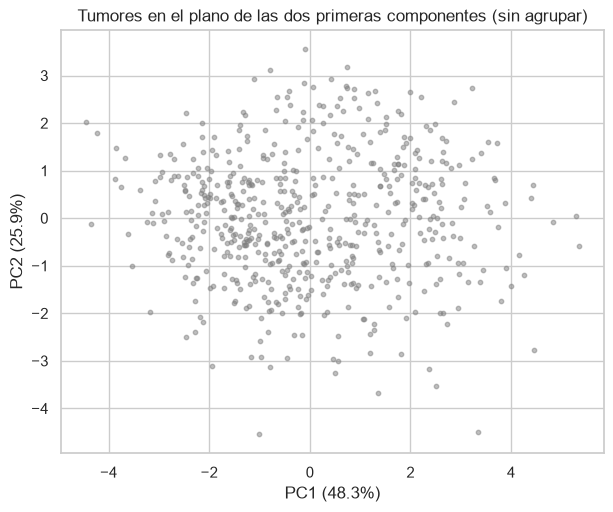

Varianza explicada por dos componentes: 74.2%


,PC1,PC2
radius_mean,0.2900,0.5800
texture_mean,0.1500,0.3600
smoothness_mean,0.4300,-0.2700
compactness_mean,0.5100,-0.0000
concave_points_mean,0.4800,0.2700
symmetry_mean,0.3800,-0.2200
fractal_dimension_mean,0.2600,-0.5800


In [17]:
# PCA solo para visualizar; los algoritmos trabajan con las siete variables completas
pca = PCA(n_components=2, random_state=SEMILLA)
X_pca = pca.fit_transform(X)
var_exp = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.scatter(X_pca[:, 0], X_pca[:, 1], s=10, alpha=0.5, color="gray")
ax.set(xlabel=f"PC1 ({var_exp[0]:.1%})", ylabel=f"PC2 ({var_exp[1]:.1%})",
       title="Tumores en el plano de las dos primeras componentes (sin agrupar)")
plt.savefig(FIGURAS / "pca_sin_agrupar.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Varianza explicada por dos componentes: {var_exp.sum():.1%}")
display(pd.DataFrame(pca.components_.T, index=VARS_MODELO, columns=["PC1", "PC2"]).round(2))

Las dos primeras componentes explican el 74,2 % de la varianza (48,3 % y 25,9 %), por lo que el plano es una representación razonable aunque no completa de los datos (Jolliffe y Cadima, 2016). Por un lado, la primera componente combina positivamente todas las variables, con mayor peso de la compacidad y los puntos cóncavos, y puede leerse como un eje general de irregularidad del contorno, por otro lado, la segunda contrapone el radio y la textura a la dimensión fractal, es decir, separa núcleos grandes de núcleos pequeños con bordes más complejos. Con lo que respecta a la forma de la nube, los tumores no se separan en islas evidentes, sino que se observa una región densa hacia valores negativos de la primera componente y una cola más dispersa hacia valores positivos. A partir de lo anterior se puede deducir que los grupos podrían no tener fronteras contundentes, de tal forma que será necesario evaluar con cuidado su separación en la validación interna. Cabe recordar que esta proyección se usa solo para visualizar y los algoritmos trabajan con las siete variables.

### 5.6 Base depurada

In [18]:
# Variables transformadas y estandarizadas: id y diagnóstico se conservan solo para la validación
df_depurado = pd.DataFrame(X, columns=VARS_MODELO)
df_depurado.insert(0, "id", df["id"].values)
df_depurado["diagnosis"] = y_ext.values

ARCHIVO_DEPURADO.parent.mkdir(parents=True, exist_ok=True)
df_depurado.to_parquet(ARCHIVO_DEPURADO, index=False)
print(f"Guardado: {ARCHIVO_DEPURADO.name} {df_depurado.shape}")

Guardado: wdbc_depurado.parquet (569, 9)


## 6. K-means

Funciones auxiliares que se reutilizan con todos los algoritmos: `plot_pca` grafica cualquier partición en el plano de las dos primeras componentes (el ruido de DBSCAN, etiqueta −1, en gris) y `tamanos` resume el porcentaje de tumores por grupo.

In [19]:
def plot_pca(labels, titulo, ax=None, centros=None):
    ax = ax or plt.subplots(figsize=(7, 5.5))[1]
    etiquetas = np.unique(labels)
    paleta = sns.color_palette("tab10", n_colors=max(len(etiquetas), 3))
    for i, l in enumerate(etiquetas):
        m = labels == l
        if l == -1:
            ax.scatter(X_pca[m, 0], X_pca[m, 1], s=8, c="lightgray", alpha=0.6, label="ruido (-1)")
        else:
            ax.scatter(X_pca[m, 0], X_pca[m, 1], s=8, alpha=0.6, color=paleta[i], label=f"Grupo {l} (n={m.sum():,})")
    if centros is not None:
        cp = pca.transform(centros)
        ax.scatter(cp[:, 0], cp[:, 1], marker="X", s=100, c="black", edgecolor="white", label="Centroides")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(titulo); ax.legend(markerscale=2, fontsize=8)
    return ax

def tamanos(labels):
    s = pd.Series(labels).value_counts().sort_index()
    return (s / s.sum() * 100).round(1).astype(str) + " %"

### 6.1 Selección del número de grupos

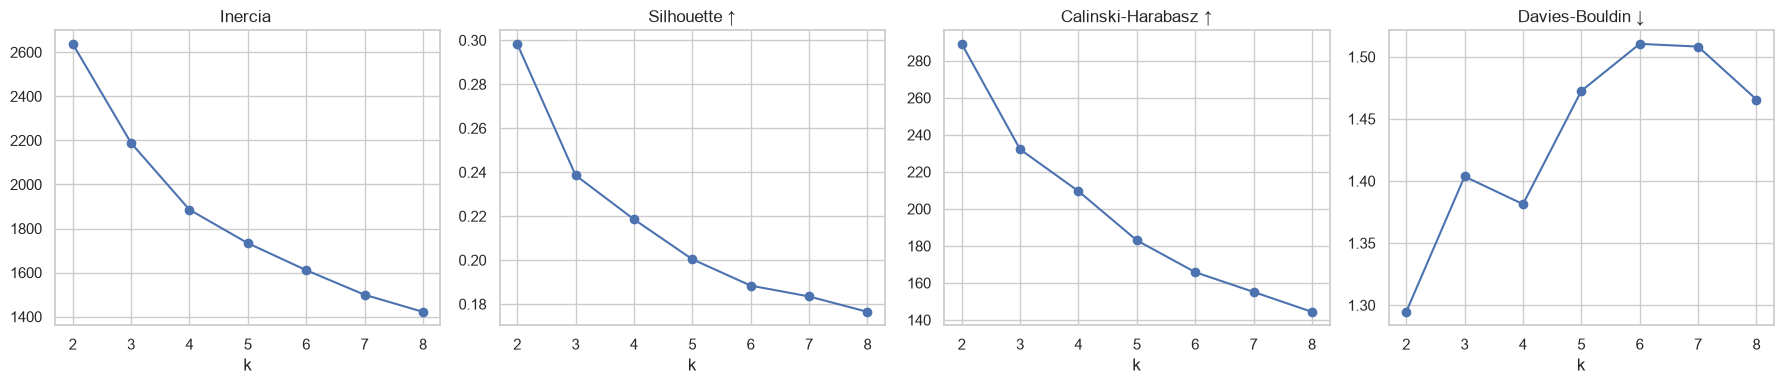

,Inercia,Silhouette,Calinski-Harabasz,Davies-Bouldin
k,,,,
2,"2,638",0.298,289,1.295
3,"2,188",0.239,232,1.404
4,"1,885",0.219,210,1.381
5,"1,733",0.200,183,1.473
6,"1,611",0.188,166,1.510
7,"1,499",0.183,155,1.508
8,"1,422",0.176,144,1.466


In [20]:
# Barrido de k con cuatro criterios internos; k_prueba evita sobrescribir la K del modelo final
k_range = range(2, 9)
res_k = []
for k_prueba in k_range:
    km = KMeans(n_clusters=k_prueba, n_init=10, random_state=SEMILLA).fit(X)
    res_k.append({"k": k_prueba, "Inercia": km.inertia_,
                  "Silhouette": silhouette_score(X, km.labels_),
                  "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_),
                  "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
                  })
res_k = pd.DataFrame(res_k).set_index("k")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (c, flecha) in zip(axes, [("Inercia", ""), ("Silhouette", "↑"), ("Calinski-Harabasz", "↑"), ("Davies-Bouldin", "↓")]):
    ax.plot(res_k.index, res_k[c], marker="o")
    ax.set_title(f"{c} {flecha}")
    ax.set_xlabel("k")

plt.tight_layout()
plt.savefig(FIGURAS / "kmeans_seleccion_k.png", dpi=150, bbox_inches="tight")
plt.show()
display(res_k.style.format({"Inercia": "{:,.0f}", "Silhouette": "{:.3f}", "Calinski-Harabasz": "{:,.0f}", "Davies-Bouldin": "{:.3f}"}))

Para elegir el número de grupos se evaluaron valores de k entre 2 y 8 con cuatro criterios internos. Tres de los criterios coinciden en k = 2, por un lado la silueta alcanza su máximo (0,298), al igual que el índice de Calinski-Harabasz (289), mientras que el índice de Davies-Bouldin registra su mínimo (1,295) (Caliński y Harabasz, 1974; Davies y Bouldin, 1979; Rousseeuw, 1987). Por otro lado, la inercia no presenta un codo marcado, ya que su reducción relativa disminuye de forma gradual (17,1 % al pasar de 2 a 3 grupos, 13,8 % de 3 a 4 y 8,1 % de 4 a 5), por lo que este criterio por sí solo no define un valor. A partir de los resultados de los 4 criterios internos evaluados, se adopta un valor de k igual a 2. A pesar de esto, una silueta de 0,30 indica una estructura débil según la escala de Kaufman y Rousseeuw (1990), lo cual es coherente con la nube continua observada en el plano de componentes principales, por esta razón, los grupos deben interpretarse como regiones diferenciadas de un continuo y no como categorías con fronteras nítidas.

### 6.2 Modelo final

Tamaño de los grupos (k-means):
0    42.0 %
1    58.0 %


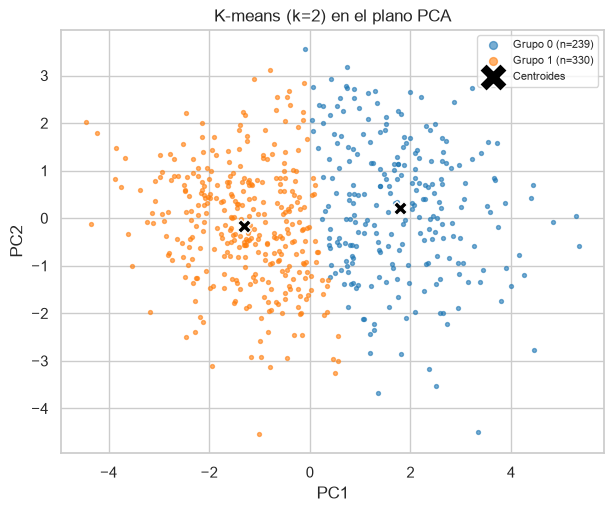

In [21]:
K = 2

kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(X)
lab_kmeans = kmeans.labels_

print("Tamaño de los grupos (k-means):")
print(tamanos(lab_kmeans).to_string())

plot_pca(lab_kmeans, f"K-means (k={K}) en el plano PCA", centros=kmeans.cluster_centers_)
plt.savefig(FIGURAS / "kmeans_pca.png", dpi=150, bbox_inches="tight")
plt.show()

El modelo final divide la muestra en un grupo de 330 tumores (58,0 %) y otro de 239 (42,0 %), los cuales se pueden distinguir en el plano de componentes principales, en el cual la separación ocurre principalmente a lo largo de la primera componente: el centroide del grupo menor se ubica en valores positivos (PC1 ≈ 1,8) y el del grupo mayor en valores negativos (PC1 ≈ −1,3). Teniendo en cuenta que esta componente resume la irregularidad del contorno, el grupo menor reúne los tumores con núcleos más grandes y contornos más irregulares; no obstante, la frontera entre ambos grupos atraviesa la región central de la nube, donde los tumores quedan a distancias similares de los dos centroides.

## 7. Clustering jerárquico

### 7.1 Dendrograma y número de grupos

In [22]:
# Árbol completo con enlace de Ward sobre las siete variables transformadas
z_ward = linkage(X, method="ward")

In [23]:
# Alturas de las últimas fusiones: un salto grande indica que se unen grupos muy distintos
alturas = z_ward[::-1, 2][:8]
tabla_saltos = pd.DataFrame({
    "grupos_antes_de_fusionar": range(2, 10),
    "altura_fusion": alturas,
    "salto_vs_siguiente": np.append(-np.diff(alturas), np.nan),
})
display(tabla_saltos.round(2))

,grupos_antes_de_fusionar,altura_fusion,salto_vs_siguiente
0,2,50.2100,21.8700
1,3,28.3400,7.0800
2,4,21.2600,2.8100
3,5,18.4500,2.2200
4,6,16.2300,1.4400
5,7,14.7900,0.7500
6,8,14.0400,0.7500
7,9,13.2900,NaN


In [24]:
# Barrido de silueta para cortes del árbol entre 2 y 8 grupos
sil_ward = []
for k_prueba in range(2, 9):
    lab = AgglomerativeClustering(n_clusters=k_prueba, linkage="ward").fit_predict(X)
    sil_ward.append({"k": k_prueba, "Silhouette": silhouette_score(X, lab),
                     "Tamaños": np.bincount(lab).tolist()})
display(pd.DataFrame(sil_ward).set_index("k").round(3))

,Silhouette,Tamaños
k,,
2,0.2710,"[286, 283]"
3,0.2260,"[283, 165, 121]"
4,0.1510,"[165, 128, 121, 155]"
5,0.1320,"[121, 128, 75, 155, 90]"
6,0.1190,"[128, 155, 75, 55, 90, 66]"
7,0.1170,"[155, 90, 75, 55, 73, 66, 55]"
8,0.1260,"[75, 57, 98, 90, 73, 66, 55, 55]"


In [25]:
# Número de grupos del jerárquico: mayor salto en las alturas de fusión
K_JER = int(tabla_saltos.loc[tabla_saltos["salto_vs_siguiente"].idxmax(), "grupos_antes_de_fusionar"])
print(f"Número de grupos elegido para el jerárquico: K_JER = {K_JER}")

Número de grupos elegido para el jerárquico: K_JER = 2


El número de grupos del jerárquico se determinó con dos criterios propios del método, sin recurrir al resultado de K-means. En primer lugar, las alturas de fusión del árbol de Ward muestran un salto marcado en la última unión: los dos grupos finales se fusionan a una altura de 50,2, mientras que la fusión anterior ocurre a 28,3, lo que representa un salto de 21,9 frente a apenas 7,1 en el paso siguiente. Teniendo en cuenta que un salto grande indica que se están uniendo grupos muy diferentes entre sí, el corte natural del árbol se ubica en dos grupos. En segundo lugar, el barrido de silueta respalda esta elección, ya que el valor máximo se obtiene con k = 2 (0,271) y disminuye de forma sostenida a partir de allí (0,226 con tres grupos y 0,151 con cuatro). Por lo previamente mencionado, se fija K_JER = 2, y el dendrograma se corta a la altura correspondiente. Cabe destacar que este resultado coincide con el de K-means, de modo que dos métodos con criterios distintos señalan la misma cantidad de grupos.

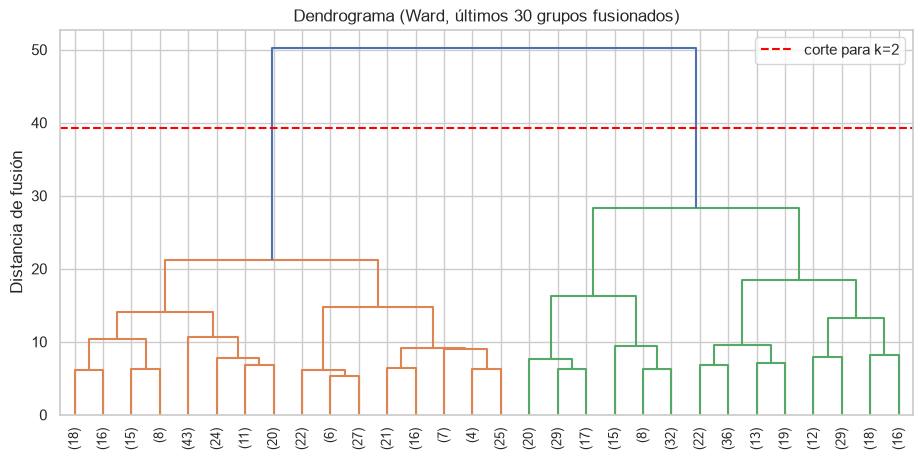

In [26]:
plt.figure(figsize=(11, 5))
dendrogram(z_ward, truncate_mode="lastp", p=30,
           show_leaf_counts=True, leaf_rotation=90,
           leaf_font_size=9)
altura_corte = (z_ward[-K_JER, 2] + z_ward[-K_JER + 1, 2]) / 2
plt.axhline(altura_corte, color="red", ls="--", label=f"corte para k={K_JER}")
plt.title("Dendrograma (Ward, últimos 30 grupos fusionados)")
plt.ylabel("Distancia de fusión")
plt.legend()
plt.savefig(FIGURAS / "jerarquico_dendrograma.png", dpi=150, bbox_inches="tight")
plt.show()

El dendrograma muestra las últimas 30 fusiones del árbol; los números entre paréntesis en el eje horizontal indican cuántos tumores contiene cada rama truncada, además, la línea roja corta el árbol a una altura cercana a 39, justo por debajo de la última fusión (50,2), y con ello separa la muestra en dos ramas: la de la izquierda (naranja), con 283 tumores, y la de la derecha (verde), con 286. La distancia vertical que recorren ambas ramas antes de unirse es la mayor de todo el árbol, lo que confirma visualmente que se trata de los dos grupos más diferenciados de la muestra.

Además, el dendrograma revela que las dos ramas no son igual de homogéneas. Por un lado, la rama naranja se consolida a una altura de 21,3, de modo que sus tumores son relativamente parecidos entre sí; este grupo reúne los núcleos con valores inferiores al promedio en todas las variables, es decir, más pequeños y de contorno más regular. Por otro lado, la rama verde se consolida recién a 28,3 y, por debajo de esa altura, se divide en dos subgrupos: uno de 121 tumores con núcleos grandes y abundantes puntos cóncavos (radio y puntos cóncavos de 1,3 y 1,2 desviaciones estándar sobre el promedio, respectivamente) y otro de 165 tumores con núcleos de tamaño cercano al promedio, pero con contornos poco suaves, compactos y de borde complejo (suavidad, compacidad y dimensión fractal entre 0,8 y 0,9 desviaciones estándar sobre el promedio). Por ende, aunque la solución de dos grupos es la mejor respaldada por los criterios internos, la rama de mayor irregularidad contiene una heterogeneidad interna que podría ser relevante para el laboratorio, ya que distingue la irregularidad asociada al tamaño de la irregularidad asociada a la forma del borde.

### 7.2 Correlación cofenética

In [27]:
d_orig = pdist(X)
coph = {}
for m in ["ward", "complete", "average", "single"]:
    coph[m] = cophenet(linkage(X, method=m), d_orig)[0]
print("Correlación cofenética por tipo de enlace:")
print(pd.Series(coph).round(3).to_string())

Correlación cofenética por tipo de enlace:
ward       0.4990
complete   0.4360
average    0.6220
single     0.4650


La correlación cofenética mide qué tan fielmente el dendrograma conserva las distancias originales entre los tumores (Sokal y Rohlf, 1962), en este caso, se observa que el enlace promedio obtiene el valor de correlación cofenética más elevado (0,62), seguido por Ward (0,50), el enlace simple (0,47) y el completo (0,44). A pesar de esto, este indicador evalúa el árbol en su conjunto y no la utilidad de un corte particular, por esta razón, un enlace puede reproducir bien las distancias globales y, aun así, producir una partición poco útil al cortarlo en pocos grupos, como se verifica en la siguiente sección.

### 7.3 Efecto de la distancia y del enlace

In [28]:
# Mismo algoritmo con distintas distancias y enlaces (ward solo admite euclidiana)
combinaciones = [("euclidean", "ward"), ("euclidean", "complete"), ("euclidean", "average"),
                 ("manhattan", "complete"), ("manhattan", "average"),
                 ("cosine", "complete"), ("cosine", "average")]

lab_dist = {}
filas = []
for metrica, enlace in combinaciones:
    lab = AgglomerativeClustering(n_clusters=K_JER, metric=metrica, linkage=enlace).fit_predict(X)
    lab_dist[(metrica, enlace)] = lab
    filas.append({"Distancia": metrica, "Enlace": enlace,
                  "Silhouette (su distancia)": silhouette_score(X, lab, metric=metrica),
                  "Silhouette (euclidiana)": silhouette_score(X, lab),
                  "% grupo más grande": np.bincount(lab).max() / len(lab) * 100,
                  "Tamaños": np.bincount(lab).tolist(),
                  "ARI vs K-means": adjusted_rand_score(lab_kmeans, lab)})
tabla_dist = pd.DataFrame(filas)
display(tabla_dist.round(3))

,Distancia,Enlace,Silhouette (su distancia),Silhouette (euclidiana),% grupo más grande,Tamaños,ARI vs K-means
0,euclidean,ward,0.2710,0.2710,50.2640,"[286, 283]",0.6960
1,euclidean,complete,0.2030,0.2030,55.7120,"[252, 317]",0.2970
2,euclidean,average,0.3200,0.3200,98.5940,"[561, 8]",0.0110
3,manhattan,complete,0.2480,0.2190,56.7660,"[323, 246]",0.4380
4,manhattan,average,0.1930,0.2010,96.6610,"[550, 19]",0.0200
5,cosine,complete,0.3870,0.2270,52.7240,"[300, 269]",0.4520
6,cosine,average,0.4350,0.2620,55.3600,"[254, 315]",0.5620


Al comparar distintas combinaciones de distancia y enlace con k = 2, el enlace promedio con distancia euclidiana alcanza la silueta más alta (0,320); no obstante, su partición es degenerada, ya que deja 561 tumores en un grupo y apenas 8 en el otro, de modo que solo aísla casos atípicos, esto mismo ocurre con la distancia Manhattan y enlace promedio (550 frente a 19). Por lo tanto, una silueta alta no es suficiente para elegir una solución, y es necesario revisar también el tamaño de los grupos. En contraste, el enlace de Ward reparte los tumores en dos grupos de tamaño similar (286 y 283) y es la combinación que más coincide con K-means (ARI = 0,70), lo cual es esperable, dado que ambos métodos minimizan la varianza dentro de los grupos (Ward, 1963). Por otra parte, el cambio de distancia modifica en gran medida la partición, ya que con el enlace completo, el ARI frente a K-means oscila entre 0,30 y 0,45 según la métrica, esto confirma que la elección de la distancia es una decisión de modelado y no un detalle técnico.

### 7.4 Modelo final

Tamaño de los grupos (jerárquico, ward):
0    50.3 %
1    49.7 %


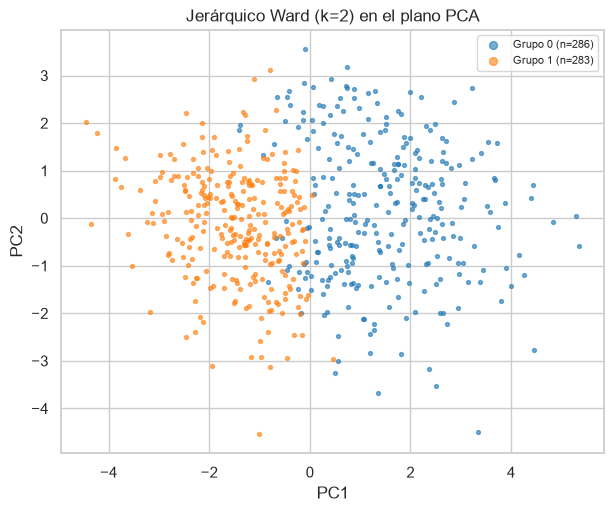

ARI entre Ward y K-means: 0.696


In [29]:
agg = AgglomerativeClustering(n_clusters=K_JER, linkage="ward").fit(X)
lab_ward = agg.labels_

print("Tamaño de los grupos (jerárquico, ward):"); print(tamanos(lab_ward).to_string())
plot_pca(lab_ward, f"Jerárquico Ward (k={K_JER}) en el plano PCA")
plt.savefig(FIGURAS / "jerarquico_ward_pca.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"ARI entre Ward y K-means: {adjusted_rand_score(lab_kmeans, lab_ward):.3f}")

El modelo final de Ward divide la muestra en dos grupos casi del mismo tamaño (50,3 % y 49,7 %), con una silueta de 0,271, ligeramente inferior a la de K-means (0,298). A diferencia del modelo generado a partir de K-means, el cual forma un grupo mayor de 330 tumores, Ward desplaza la frontera hacia el centro de la nube y equilibra los tamaños, a pesar de esto, ambas particiones coinciden en buena medida (ARI = 0,70), por lo que describen esencialmente la misma división entre tumores de núcleos pequeños y regulares y tumores de núcleos grandes e irregulares.

## 8. DBSCAN

### 8.1 Parámetros

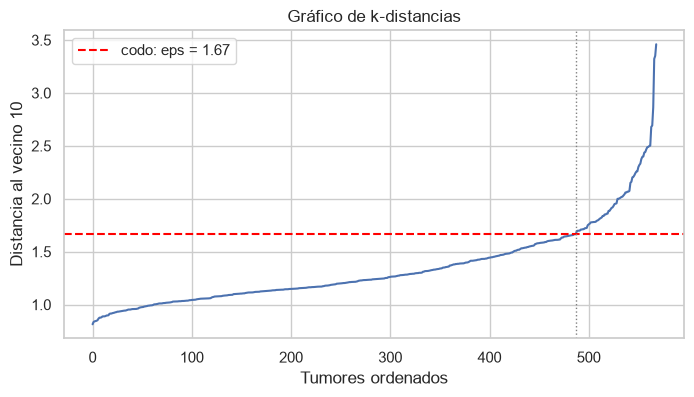

eps en el codo: 1.67 (tumor 487 de 569)


In [30]:
# Densidad mínima: entre dimensiones + 1 (8) y 2 × dimensiones (14)
MIN_S = 10
nn = NearestNeighbors(n_neighbors=MIN_S).fit(X)
kdist = np.sort(nn.kneighbors(X)[0][:, -1])

# Codo: punto de la curva normalizada más alejado de la diagonal (criterio tipo kneedle)
x_norm = np.linspace(0, 1, len(kdist))
y_norm = (kdist - kdist.min()) / (kdist.max() - kdist.min())
idx_codo = int(np.argmax(x_norm - y_norm))
EPS = round(float(kdist[idx_codo]), 2)

plt.figure(figsize=(8, 4))
plt.plot(kdist)
plt.axhline(EPS, color="red", ls="--", label=f"codo: eps = {EPS}")
plt.axvline(idx_codo, color="gray", ls=":", lw=1)
plt.xlabel("Tumores ordenados")
plt.ylabel(f"Distancia al vecino {MIN_S}")
plt.title("Gráfico de k-distancias")
plt.legend()
plt.savefig(FIGURAS / "dbscan_k_distancias.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"eps en el codo: {EPS} (tumor {idx_codo} de {len(kdist)})")

DBSCAN define los grupos como regiones de alta densidad separadas por zonas de baja densidad, y depende de dos parámetros: `min_samples`, el número mínimo de vecinos para que un punto sea núcleo, y `eps`, el radio de vecindad (Ester et al., 1996). Para `min_samples` se adoptó un valor de 10, intermedio entre la regla mínima de dimensiones + 1 (8) y la recomendación de 2 × dimensiones (14) propuesta por Sander et al. (1998). Por su parte, `eps` se eligió a partir del gráfico de k-distancias, que ordena la distancia de cada tumor a su décimo vecino; el codo de la curva, identificado como el punto más alejado de la diagonal de la curva normalizada (Satopää et al., 2011), se ubica en el tumor 487 de 569, con una distancia de 1,67. Sin embargo, la curva sube de forma gradual y sin un escalón pronunciado, lo que anticipa que la densidad cambia de manera continua y que no existen zonas vacías que separen grupos.

### 8.2 Sensibilidad a los parámetros

In [31]:
# Sensibilidad del resultado a eps y min_samples
filas = []
for ms in [8, MIN_S, 14]:
    for eps in [0.8, 1.0, 1.2, 1.4, 1.6, EPS, 1.8, 2.0]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        en_grupo = lab >= 0
        filas.append({"min_samples": ms, "eps": eps,
                      "grupos": len(set(lab)) - (1 if -1 in lab else 0),
                      "% ruido": (~en_grupo).mean() * 100,
                      "tamaños": np.bincount(lab[en_grupo]).tolist() if en_grupo.any() else []})
sens = pd.DataFrame(filas)
display(sens.pivot(index="eps", columns="min_samples", values="grupos").rename_axis(columns="Nº de grupos"))
display(sens.pivot(index="eps", columns="min_samples", values="% ruido").round(1).rename_axis(columns="% ruido"))

Nº de grupos,8,10,14
eps,,,
0.8000,5,0,0
1.0000,1,1,4
1.2000,1,1,1
1.4000,1,1,1
1.6000,1,1,1
1.6700,1,1,1
1.8000,1,1,1
2.0000,1,1,1


% ruido,8,10,14
eps,,,
0.8000,91.7000,100.0000,100.0000
1.0000,52.4000,61.7000,78.4000
1.2000,22.1000,26.0000,33.2000
1.4000,10.9000,11.8000,14.1000
1.6000,3.9000,5.4000,6.9000
1.6700,3.5000,3.5000,6.0000
1.8000,2.6000,2.8000,3.0000
2.0000,0.9000,0.9000,1.1000


Como se anticipó en la sección de parámetros la tabla de sensibilidad confirma que con valores pequeños de `eps` (0,8 a 1,0), la mayoría de los tumores queda como ruido y solo aparecen fragmentos de entre 7 y 50 casos, en cambio, a partir de un valor de `eps` = 1,2, todos los tumores densos se unen en un único grupo y lo único que varía es la proporción de ruido, el cual disminuye a medida que aumenta el radio. Teniendo esto en cuenta, se observó que en los tres valores de `min_samples` evaluados en todos se repite este mismo patrón, por lo que no existe ninguna combinación razonable que sea capaz de producir dos o más grupos de tamaño comparable. Por lo tanto, la ausencia de grupos no se debe a una mala elección de parámetros, sino a la estructura de los datos: los tumores forman un continuo sin regiones de baja densidad que los separen, lo cual es coherente con la nube continua del plano de componentes principales y con las siluetas débiles de K-means y Ward.

### 8.3 Modelo final y tumores atípicos

Grupos: 1 | ruido: 20 (3.5%)
-1     20
 0    549


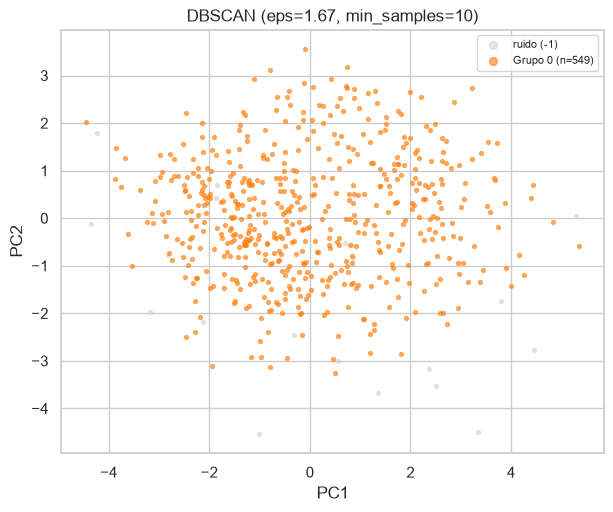

In [32]:
db = DBSCAN(eps=EPS, min_samples=MIN_S).fit(X)
lab_db = db.labels_
n_g = len(set(lab_db)) - (1 if -1 in lab_db else 0)
print(f"Grupos: {n_g} | ruido: {(lab_db == -1).sum():,} ({(lab_db == -1).mean():.1%})")
print(pd.Series(lab_db).value_counts().sort_index().to_string())

plot_pca(lab_db, f"DBSCAN (eps={EPS}, min_samples={MIN_S})")
plt.savefig(FIGURAS / "dbscan_pca.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
# Perfil de los tumores marcados como ruido frente al resto (escala estandarizada)
es_ruido = lab_db == -1
X_df = pd.DataFrame(X, columns=VARS_MODELO)
perfil_ruido = pd.DataFrame({"ruido": X_df[es_ruido].mean(), "resto": X_df[~es_ruido].mean()})
display(perfil_ruido.round(2))

# Desviación máxima de cada tumor en cualquier variable: qué tan extremo es
max_abs = X_df.abs().max(axis=1)
print(f"Máxima |z| promedio: ruido = {max_abs[es_ruido].mean():.2f} | resto = {max_abs[~es_ruido].mean():.2f}")

,ruido,resto
radius_mean,-1.2000,0.0400
texture_mean,-0.1500,0.0100
smoothness_mean,0.2600,-0.0100
compactness_mean,0.2100,-0.0100
concave_points_mean,-0.2900,0.0100
symmetry_mean,0.5600,-0.0200
fractal_dimension_mean,1.1100,-0.0400


Máxima |z| promedio: ruido = 2.74 | resto = 1.50


Con los parámetros elegidos, DBSCAN agrupa 549 tumores en un único grupo y marca 20 (3,5 %) como ruido. En consecuencia, este método no sirve para segmentar la muestra en subgrupos, pero sí cumple una función complementaria como detector de casos atípicos. Los tumores marcados como ruido presentan, en promedio, núcleos más pequeños (radio de −1,2 desviaciones estándar) y bordes más complejos (dimensión fractal de +1,1), y su desviación máxima en alguna variable es de 2,74 desviaciones estándar frente a 1,50 en el resto de la muestra. A partir de lo anterior, se puede decir que los tumores marcados como ruido son en verdad combinaciones poco frecuentes de características, que el laboratorio podría priorizar para revisión individual, independientemente del grupo que les asignen los otros métodos.

## 9. Comparación de técnicas

In [34]:
def dunn_index(X_, labels_):
    # Índice de Dunn: mínima distancia entre grupos / máximo diámetro de un grupo (↑ mejor)
    grupos = [X_[labels_ == g] for g in np.unique(labels_)]
    diametro = max(pdist(g).max() for g in grupos if len(g) > 1)
    separacion = min(cdist(grupos[i], grupos[j]).min()
                     for i in range(len(grupos)) for j in range(i + 1, len(grupos)))
    return separacion / diametro

def evaluar(X_, labels_, nombre):
    # Métricas internas sobre los tumores asignados a un grupo; el ruido de DBSCAN se reporta aparte
    labels_ = np.asarray(labels_)
    en_grupo = labels_ != -1
    Xe, le = X_[en_grupo], labels_[en_grupo]
    fila = {"Método": nombre, "Grupos": len(np.unique(le)), "% ruido": (~en_grupo).mean() * 100,
            "% grupo más grande": np.bincount(le).max() / len(le) * 100}
    if len(np.unique(le)) > 1:
        fila.update({"Silhouette ↑": silhouette_score(Xe, le),
                     "Davies-Bouldin ↓": davies_bouldin_score(Xe, le),
                     "Calinski-Harabasz ↑": calinski_harabasz_score(Xe, le),
                     "Dunn ↑": dunn_index(Xe, le)})
    return fila

particiones = {
    f"K-means (k={K})": lab_kmeans,
    f"Jerárquico Ward (k={K_JER})": lab_ward,
    f"DBSCAN (eps={EPS}, ms={MIN_S})": lab_db,
}
comparacion = pd.DataFrame([evaluar(X, lab, nombre) for nombre, lab in particiones.items()]).set_index("Método")
display(comparacion.round(3))

,Grupos,% ruido,% grupo más grande,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,Dunn ↑
Método,,,,,,,
K-means (k=2),2,0.0000,57.9960,0.2980,1.2950,289.1430,0.0600
Jerárquico Ward (k=2),2,0.0000,50.2640,0.2710,1.3740,262.4890,0.0720
"DBSCAN (eps=1.67, ms=10)",1,3.5150,100.0000,NaN,NaN,NaN,NaN


Al comparar las tres técnicas con las mismas métricas y sobre los mismos datos, K-means obtiene los mejores valores en tres de los cuatro índices: la silueta más alta (0,298), el menor Davies-Bouldin (1,295) y el mayor Calinski-Harabasz (289), frente a 0,271, 1,374 y 262 de Ward. Por su parte, el índice de Dunn es ligeramente mayor en Ward (0,072 frente a 0,060), aunque en ambos casos es muy bajo, dado que basta un par de tumores cercanos a la frontera para reducir la distancia mínima entre grupos. Cabe aclarar que estas métricas se basan en distancias euclidianas, de modo que tienden a favorecer a K-means, que optimiza precisamente ese criterio, por lo que, la comparación interna debe complementarse con la validación individual y externa. Para finalizar, cabe resaltar que DBSCAN no admite el cálculo de las métricas evaluadas, esto debido a que produce un único grupo, por lo que su desempeño se evalúa en términos de su capacidad para identificar casos atípicos.

## 10. Validación interna
### 10.1 Silueta por tumor

In [35]:
sil_km = silhouette_samples(X, lab_kmeans)
sil_ward = silhouette_samples(X, lab_ward)

resumen_sil = pd.DataFrame({
    "K-means": [sil_km.mean(), (sil_km < 0).mean() * 100, (sil_km > 0.5).mean() * 100],
    "Ward": [sil_ward.mean(), (sil_ward < 0).mean() * 100, (sil_ward > 0.5).mean() * 100],
}, index=["Silhouette medio", "% tumores con s(i) < 0", "% tumores con s(i) > 0,5"])
display(resumen_sil.round(3))

# Silueta media y proporción de tumores mal asignados por grupo
display(pd.DataFrame({
    "K-means s(i) medio": pd.Series(sil_km).groupby(lab_kmeans).mean(),
    "K-means % s(i) < 0": pd.Series(sil_km < 0).groupby(lab_kmeans).mean() * 100,
    "Ward s(i) medio": pd.Series(sil_ward).groupby(lab_ward).mean(),
    "Ward % s(i) < 0": pd.Series(sil_ward < 0).groupby(lab_ward).mean() * 100,
}).round(3).rename_axis("Grupo"))

,K-means,Ward
Silhouette medio,0.2980,0.2710
% tumores con s(i) < 0,0.3510,6.5030
"% tumores con s(i) > 0,5",0.0000,0.0000


,K-means s(i) medio,K-means % s(i) < 0,Ward s(i) medio,Ward % s(i) < 0
Grupo,,,,
0,0.2900,0.4180,0.2280,12.5870
1,0.3040,0.3030,0.3150,0.3530


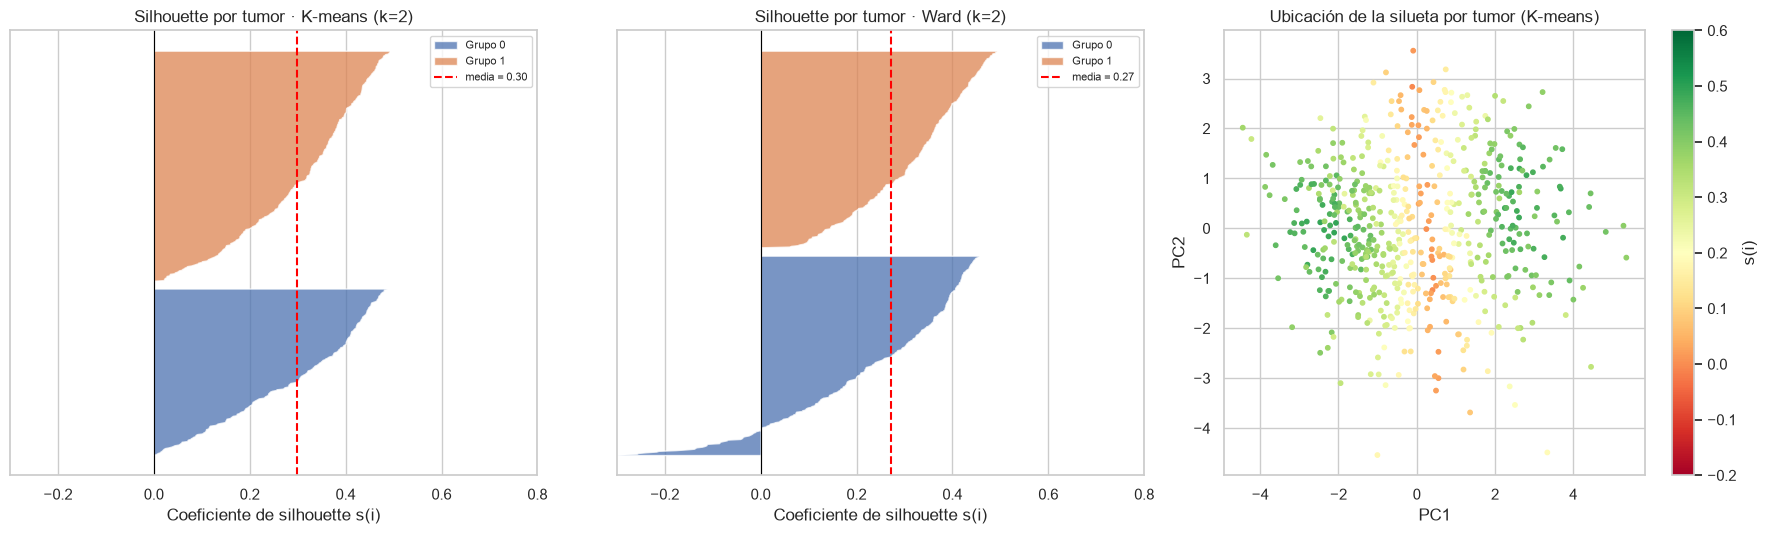

In [36]:
def grafico_silueta(s, labels_, titulo, ax):
    # Barras horizontales de s(i) ordenadas dentro de cada grupo
    y_inf = 10
    for g in np.unique(labels_):
        v = np.sort(s[labels_ == g])
        ax.fill_betweenx(np.arange(y_inf, y_inf + len(v)), 0, v, alpha=0.75, label=f"Grupo {g}")
        y_inf += len(v) + 10
    ax.axvline(s.mean(), color="red", ls="--", label=f"media = {s.mean():.2f}")
    ax.axvline(0, color="black", lw=0.8)
    ax.set(xlim=(-0.3, 0.8), yticks=[], xlabel="Coeficiente de silhouette s(i)", title=titulo)
    ax.legend(fontsize=8)

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
grafico_silueta(sil_km, lab_kmeans, f"Silhouette por tumor · K-means (k={K})", ax[0])
grafico_silueta(sil_ward, lab_ward, f"Silhouette por tumor · Ward (k={K_JER})", ax[1])
sc = ax[2].scatter(X_pca[:, 0], X_pca[:, 1], c=sil_km, cmap="RdYlGn", vmin=-0.2, vmax=0.6, s=10)
plt.colorbar(sc, ax=ax[2], label="s(i)")
ax[2].set(title="Ubicación de la silueta por tumor (K-means)", xlabel="PC1", ylabel="PC2")
plt.tight_layout()
plt.savefig(FIGURAS / "validacion_silueta.png", dpi=150, bbox_inches="tight")
plt.show()

La silueta individual permite evaluar qué tan bien asignado está cada tumor, y no solo el promedio de la partición (Rousseeuw, 1987). En K-means, únicamente el 0,4 % de los tumores tiene un coeficiente negativo, es decir, casi ningún tumor queda más cerca del grupo vecino que del propio; además, la silueta media es similar en los dos grupos (0,29 y 0,30). Sin embargo, ningún tumor supera el valor de 0,5, lo que indica que la mayoría se ubica en una zona intermedia y que ninguno pertenece a su grupo de forma contundente. En contraste, Ward presenta un 6,5 % de tumores con silueta negativa, concentrados en el grupo de núcleos más irregulares (12,6 % de ese grupo), de modo que, con una silueta media parecida, la calidad de la asignación individual es claramente inferior. Por otra parte, el mapa de la derecha muestra que los tumores con silueta baja se concentran en la franja central del plano de componentes principales, que corresponde a la frontera entre los dos grupos.

### 10.2 Separación entre grupos

In [37]:
# Distancia entre centroides frente a la dispersión interna de cada grupo (K-means)
grupos_km = np.unique(lab_kmeans)
centroides = np.array([X[lab_kmeans == g].mean(axis=0) for g in grupos_km])
dist_centroides = np.linalg.norm(centroides[0] - centroides[1])
radios = np.array([np.linalg.norm(X[lab_kmeans == g] - centroides[i], axis=1).mean()
                   for i, g in enumerate(grupos_km)])

print(f"Distancia entre centroides: {dist_centroides:.2f}")
display(pd.DataFrame({"n": np.bincount(lab_kmeans), "radio medio": radios,
                      "separación / radio": dist_centroides / radios},
                     index=[f"Grupo {g}" for g in grupos_km]).round(2))

Distancia entre centroides: 3.12


,n,radio medio,separación / radio
Grupo 0,239,2.0300,1.5300
Grupo 1,330,2.0000,1.5600


La distancia entre los centroides de K-means es de 3,12, mientras que el radio medio de cada grupo, es decir, la distancia promedio de sus tumores al centroide, es de 2,0, por lo que, la razón entre separación y radio se ubica entre 1,53 y 1,56; como referencia, valores superiores a 2 indicarían grupos claramente separados, mientras que valores cercanos a 1 indicarían grupos que se tocan. Teniendo esto en cuenta, los centroides están separados, pero los grupos se solapan en su periferia, lo que es coherente con la silueta individual y con la ausencia de zonas de baja densidad que se detectaron con DBSCAN.

## 11. Validación externa

La validación externa compara las particiones con información que los algoritmos no utilizaron. Se aborda desde tres frentes: la concordancia entre métodos y la estabilidad frente a cambios en la muestra o en las variables, que no requieren etiquetas, y el contraste con el diagnóstico, que se usa aquí por primera vez.

### 11.1 Concordancia entre métodos

In [38]:
filas = []
nombres = list(particiones.keys())
for i, a in enumerate(nombres):
    for b in nombres[i + 1:]:
        filas.append({"Par": f"{a} vs {b}",
                      "ARI": adjusted_rand_score(particiones[a], particiones[b]),
                      "NMI": normalized_mutual_info_score(particiones[a], particiones[b])})
display(pd.DataFrame(filas).set_index("Par").round(3))

,ARI,NMI
Par,,
K-means (k=2) vs Jerárquico Ward (k=2),0.6960,0.6640
"K-means (k=2) vs DBSCAN (eps=1.67, ms=10)",0.0030,0.0010
"Jerárquico Ward (k=2) vs DBSCAN (eps=1.67, ms=10)",-0.0000,0.0000


K-means y Ward coinciden en buena medida (ARI = 0,70; NMI = 0,66), lo cual indica que dos algoritmos con criterios distintos recuperan esencialmente la misma división de la muestra (Hubert y Arabie, 1985). En cambio, DBSCAN no coincide con ninguno de los dos (ARI ≈ 0), lo que es esperable, ya que agrupa a casi todos los tumores en un único conjunto.

### 11.2 Estabilidad por remuestreo

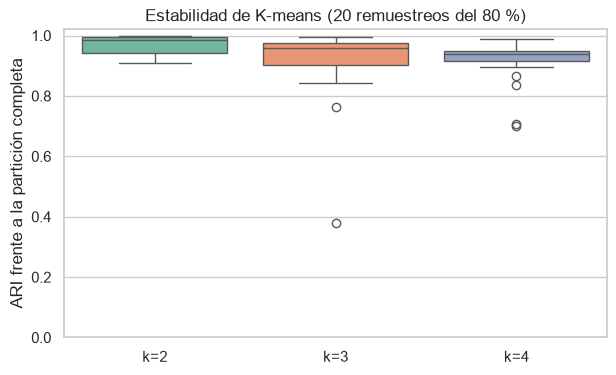

,ARI medio,desv.
k=2,0.9670,0.0350
k=3,0.9110,0.1390
k=4,0.9110,0.0800


In [39]:
# Se ajusta K-means en el 80 % de los tumores y se compara con la partición de la muestra completa
def estabilidad(k, n_rep=20, frac=0.8, seed=SEMILLA):
    rs = np.random.RandomState(seed)
    base = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X).predict(X)
    aris = []
    for _ in range(n_rep):
        idx = rs.choice(len(X), int(frac * len(X)), replace=False)
        pred = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X[idx]).predict(X)
        aris.append(adjusted_rand_score(base, pred))
    return np.array(aris)

est = pd.DataFrame({f"k={k_prueba}": estabilidad(k_prueba) for k_prueba in [2, 3, 4]})

plt.figure(figsize=(7, 4))
sns.boxplot(data=est, palette="Set2")
plt.ylabel("ARI frente a la partición completa")
plt.title("Estabilidad de K-means (20 remuestreos del 80 %)")
plt.ylim(0, 1.02)
plt.savefig(FIGURAS / "validacion_estabilidad.png", dpi=150, bbox_inches="tight")
plt.show()
display(est.agg(["mean", "std"]).T.rename(columns={"mean": "ARI medio", "std": "desv."}).round(3))

La partición de K-means con dos grupos es muy estable, ya que al reajustar el modelo sobre subconjuntos aleatorios del 80 % de la muestra, el ARI medio frente a la partición completa es de 0,97 con una desviación aproximada de 0,04. Por otro lado, cuando la partición de K-means se hace con tres y cuatro grupos, la estabilidad se ve afectada disminuyendo a 0,91 en ambas particiones, además de aumentar su variabilidad, en especial con tres grupos con una desviación de 0,14, esto refuerza la elección de k = 2. A pesar de esto, cabe resaltar que la estabilidad no equivale a separación, ya que un continuo puede dividirse siempre por el mismo lugar aun sin fronteras naturales, por lo que ambas evidencias deben leerse en conjunto.

### 11.3 Robustez frente al bloque de variables

In [40]:
# Mismas siete medidas en su versión peor (_worst), con el mismo preprocesamiento
VARS_WORST = [v.replace("_mean", "_worst") for v in VARS_MODELO]
X_worst = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(df_cluster[VARS_WORST])
lab_kmeans_worst = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit_predict(X_worst)

print(f"Tamaños con el bloque _worst: {np.bincount(lab_kmeans_worst).tolist()}")
print(f"Silhouette con el bloque _worst: {silhouette_score(X_worst, lab_kmeans_worst):.3f}")
print(f"ARI entre las particiones _mean y _worst: {adjusted_rand_score(lab_kmeans, lab_kmeans_worst):.3f}")

Tamaños con el bloque _worst: [341, 228]
Silhouette con el bloque _worst: 0.321
ARI entre las particiones _mean y _worst: 0.583


Para evaluar si la segmentación depende de haber elegido el bloque de variables medias, se repitió K-means con las mismas siete medidas en su versión peor. El resultado conserva la estructura general, con dos grupos de 341 y 228 tumores y una silueta de 0,321, y coincide moderadamente con la partición principal (ARI = 0,58). Por lo tanto, la división en dos grupos no es un artefacto del bloque elegido, aunque la asignación de los tumores cercanos a la frontera sí cambia según se describa el núcleo típico o los núcleos más extremos de cada muestra.

### 11.4 Contraste con el diagnóstico

In [41]:
# Primera vez que se usa el diagnóstico: solo para evaluar las particiones ya fijadas
filas = []
for nombre, lab in [(f"K-means (k={K})", lab_kmeans), (f"Jerárquico Ward (k={K_JER})", lab_ward)]:
    h, c, v = homogeneity_completeness_v_measure(y_ext, lab)
    filas.append({"Método": nombre, "ARI": adjusted_rand_score(y_ext, lab),
                  "NMI": normalized_mutual_info_score(y_ext, lab),
                  "Homogeneidad": h, "Completitud": c, "V-measure": v})
display(pd.DataFrame(filas).set_index("Método").round(3))

for nombre, lab in [("K-means", lab_kmeans), ("Ward", lab_ward)]:
    print(f"\nTabla cruzada {nombre} × diagnóstico")
    display(pd.crosstab(pd.Series(lab, name="Grupo"), y_ext, margins=True))
    display((pd.crosstab(pd.Series(lab, name="Grupo"), y_ext, normalize="index") * 100).round(1))

print("Diagnóstico de los tumores atípicos de DBSCAN:", y_ext[lab_db == -1].value_counts().to_dict())

,ARI,NMI,Homogeneidad,Completitud,V-measure
Método,,,,,
K-means (k=2),0.4610,0.3590,0.3650,0.3540,0.3590
Jerárquico Ward (k=2),0.3580,0.3180,0.3260,0.3100,0.3180



Tabla cruzada K-means × diagnóstico


diagnosis,B,M,All
Grupo,,,
0,59,180,239
1,298,32,330
All,357,212,569


diagnosis,B,M
Grupo,,
0,24.7000,75.3000
1,90.3000,9.7000



Tabla cruzada Ward × diagnóstico


diagnosis,B,M,All
Grupo,,,
0,94,192,286
1,263,20,283
All,357,212,569


diagnosis,B,M
Grupo,,
0,32.9000,67.1000
1,92.9000,7.1000


Diagnóstico de los tumores atípicos de DBSCAN: {'B': 17, 'M': 3}


Al contrastar las particiones con el diagnóstico, K-means muestra la mayor concordancia (ARI = 0,46; NMI = 0,36), por encima de Ward (ARI = 0,36; NMI = 0,32). En K-means, el grupo de núcleos grandes e irregulares está compuesto en un 75,3 % por tumores malignos (180 de 239), mientras que el grupo de núcleos pequeños y regulares es benigno en un 90,3 % (298 de 330). Dicho de otro modo, el grupo irregular concentra el 84,9 % de los tumores malignos de la muestra (180 de 212). Por su parte, Ward eleva la pureza del grupo regular (92,9 % benignos), pero a costa de un grupo irregular más mezclado (67,1 % malignos). Cabe resaltar que estas cifras no se usaron en ningún paso previo: las variables, el número de grupos y los parámetros se fijaron sin el diagnóstico, de modo que la concordancia obtenida refleja estructura real de los datos y no un ajuste a la etiqueta. Sin embargo, la concordancia es moderada, lo cual es coherente con la estructura débil detectada en la validación interna. En cuanto a los 20 tumores atípicos identificados por DBSCAN, 17 son benignos y 3 malignos.

## 12. Perfilamiento de los grupos

In [42]:
# Nombre descriptivo de cada grupo de K-means según su nivel de puntos cóncavos
medias_z = pd.DataFrame(X, columns=VARS_MODELO).groupby(lab_kmeans).mean()
grupo_irregular = medias_z["concave_points_mean"].idxmax()
NOMBRES_GRUPO = {g: ("Núcleos grandes e irregulares" if g == grupo_irregular else "Núcleos pequeños y regulares")
                 for g in medias_z.index}

# Perfil en escala original (medianas) y composición diagnóstica
perfil = df[VARS_MODELO].groupby(lab_kmeans).median().T
perfil.columns = [NOMBRES_GRUPO[g] for g in perfil.columns]
perfil.loc["n tumores"] = pd.Series(lab_kmeans).value_counts().sort_index().values
perfil.loc["% malignos"] = (pd.crosstab(lab_kmeans, y_ext, normalize="index")["M"] * 100).values
display(perfil.round(4))

,Núcleos grandes e irregulares,Núcleos pequeños y regulares
radius_mean,16.1100,12.2850
texture_mean,20.3800,17.9150
smoothness_mean,0.1054,0.0880
compactness_mean,0.1353,0.0688
concave_points_mean,0.0817,0.0226
symmetry_mean,0.1943,0.1669
fractal_dimension_mean,0.0638,0.0601
n tumores,239.0000,330.0000
% malignos,75.3138,9.6970


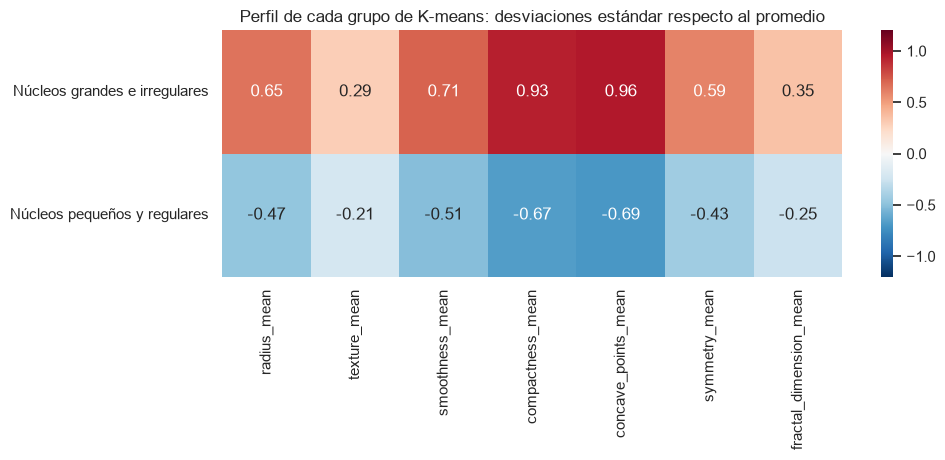

In [43]:
plt.figure(figsize=(10, 3.2))
sns.heatmap(medias_z.rename(index=NOMBRES_GRUPO), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1.2, vmax=1.2)
plt.title("Perfil de cada grupo de K-means: desviaciones estándar respecto al promedio")
plt.ylabel("")
plt.savefig(FIGURAS / "perfil_grupos.png", dpi=150, bbox_inches="tight")
plt.show()

El perfilamiento en la escala original permite describir los grupos en términos que el laboratorio puede interpretar, a partir de esto es importante destacar que el grupo de núcleos pequeños y regulares (330 tumores) presenta un radio mediano de 12,3 frente a 16,1 del otro grupo, y valores inferiores al promedio en todas las variables; las mayores diferencias se encuentran en los puntos cóncavos (mediana de 0,023 frente a 0,082) y en la compacidad (0,069 frente a 0,135), es decir, en la regularidad del contorno. Por otro lado, el grupo de núcleos grandes e irregulares (239 tumores) se ubica entre 0,6 y 1,0 desviaciones estándar por encima del promedio en tamaño, compacidad, puntos cóncavos y suavidad, y concentra el 75,3 % de tumores malignos. A partir de lo anterior, se concluye que este resultado es coherente con la literatura, según la cual los núcleos malignos tienden a ser más grandes y a presentar contornos más irregulares (Wolberg, Street, et al., 1995). Finalmente, la textura y la dimensión fractal son las variables que menos diferencian a los grupos, por lo que la segmentación se apoya principalmente en el tamaño y la irregularidad del contorno.

## 13. Conclusiones y recomendación

En síntesis, el análisis de agrupamiento identifica dos perfiles morfológicos de tumores mamarios que pueden orientar las decisiones del laboratorio. El primero, de núcleos grandes e irregulares, reúne el 42 % de la muestra y está compuesto mayoritariamente por tumores malignos (75,3 %); el segundo, de núcleos pequeños y regulares, reúne el 58 % y es benigno en un 90,3 %. Por lo tanto, el perfil morfológico de un tumor nuevo, calculado con el mismo transformador ajustado en el preprocesamiento, podría utilizarse para priorizar su análisis: los casos asignados al grupo irregular se dirigirían a una ruta de revisión prioritaria, mientras que los del grupo regular seguirían una ruta rutinaria. Adicionalmente, los tumores que DBSCAN identifica como atípicos constituyen una tercera ruta de revisión individual, independientemente del grupo asignado.

Entre las técnicas evaluadas, se recomienda K-means. En primer lugar, obtiene los mejores valores en tres de los cuatro índices internos y la menor proporción de tumores mal asignados (0,4 % frente a 6,5 % de Ward); en segundo lugar, su partición es muy estable frente a cambios en la muestra (ARI de 0,97); y, en tercer lugar, es la que mejor concuerda con el diagnóstico (ARI = 0,46). Además, a diferencia del jerárquico, permite asignar tumores nuevos directamente al centroide más cercano. Por su parte, el jerárquico de Ward confirma de forma independiente la existencia de dos grupos, y DBSCAN aporta la detección de casos atípicos, aunque no sirve para segmentar la muestra.

No obstante, estos resultados tienen limitaciones que deben considerarse. La estructura de grupos es débil (silueta de 0,30) y los datos forman un continuo, de modo que los grupos deben entenderse como regiones de un gradiente morfológico y no como categorías con fronteras nítidas. En consecuencia, el grupo regular contiene 32 tumores malignos (9,7 %), por lo que la segmentación no puede reemplazar el diagnóstico citológico y su uso debe limitarse a priorizar, nunca a descartar casos.

## Referencias

Caliński, T., & Harabasz, J. (1974). A dendrite method for cluster analysis. *Communications in Statistics, 3*(1), 1–27. https://doi.org/10.1080/03610927408827101

Davies, D. L., & Bouldin, D. W. (1979). A cluster separation measure. *IEEE Transactions on Pattern Analysis and Machine Intelligence, PAMI-1*(2), 224–227. https://doi.org/10.1109/TPAMI.1979.4766909

Ester, M., Kriegel, H.-P., Sander, J., & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. En *Proceedings of the Second International Conference on Knowledge Discovery and Data Mining* (pp. 226–231). AAAI Press.

Hubert, L., & Arabie, P. (1985). Comparing partitions. *Journal of Classification, 2*(1), 193–218. https://doi.org/10.1007/BF01908075

James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An introduction to statistical learning: With applications in R* (2.ª ed.). Springer. https://doi.org/10.1007/978-1-0716-1418-1

Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202

Kaufman, L., & Rousseeuw, P. J. (1990). *Finding groups in data: An introduction to cluster analysis*. Wiley. https://doi.org/10.1002/9780470316801

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7

Sander, J., Ester, M., Kriegel, H.-P., & Xu, X. (1998). Density-based clustering in spatial databases: The algorithm GDBSCAN and its applications. *Data Mining and Knowledge Discovery, 2*(2), 169–194. https://doi.org/10.1023/A:1009745219419

Satopää, V., Albrecht, J., Irwin, D., & Raghavan, B. (2011). Finding a "kneedle" in a haystack: Detecting knee points in system behavior. En *2011 31st International Conference on Distributed Computing Systems Workshops* (pp. 166–171). IEEE. https://doi.org/10.1109/ICDCSW.2011.20

Schober, P., Boer, C., & Schwarte, L. A. (2018). Correlation coefficients: Appropriate use and interpretation. *Anesthesia & Analgesia, 126*(5), 1763–1768. https://doi.org/10.1213/ANE.0000000000002864

Sokal, R. R., & Rohlf, F. J. (1962). The comparison of dendrograms by objective methods. *Taxon, 11*(2), 33–40. https://doi.org/10.2307/1217208

Street, W. N., Wolberg, W. H., & Mangasarian, O. L. (1993). Nuclear feature extraction for breast tumor diagnosis. En *Proceedings of SPIE 1905: Biomedical Image Processing and Biomedical Visualization* (pp. 861–870). https://doi.org/10.1117/12.148698

Tukey, J. W. (1977). *Exploratory data analysis*. Addison-Wesley.

Ward, J. H., Jr. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236–244. https://doi.org/10.1080/01621459.1963.10500845

Wolberg, W., Mangasarian, O., Street, N., & Street, W. (1995). *Breast Cancer Wisconsin (Diagnostic)* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B

Wolberg, W. H., Street, W. N., Heisey, D. M., & Mangasarian, O. L. (1995). Computer-derived nuclear features distinguish malignant from benign breast cytology. *Human Pathology, 26*(7), 792–796.

Yeo, I.-K., & Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika, 87*(4), 954–959. https://doi.org/10.1093/biomet/87.4.954